# ДЗ до теми 8 «Детекція обʼєктів: аналіз результатів»: детекція обʼєктів у приміщенні (YOLOv9s)

Студент: Фарід Джафарлі. Курс: Deep Learning for Computer Vision and NLP (GoIT).

Дані: [Indoor Objects Detection](https://www.kaggle.com/datasets/thepbordin/indoor-object-detection), зображення інтерʼєрів з розміткою у форматі YOLO. У датасеті 10 класів: `door` (двері), `cabinetDoor` (дверцята шафи), `refrigeratorDoor` (дверцята холодильника), `window` (вікно), `chair` (стілець), `table` (стіл), `cabinet` (шафа), `couch` (диван / кушетка), `openedDoor` (відчинені двері), `pole` (стовп / колона). Автор датасету вже поділив його на train / valid / test.

Мета: навчити детектор YOLO, який знаходить і розпізнає обʼєкти інтерʼєру, оцінити його на валідаційній вибірці (і додатково на тестовій), розібрати криві навчання, метрики по класах і матрицю помилок, а потім запропонувати конкретні покращення. Мінімальна вимога: модель має надійно розпізнавати хоча б 3 з 10 класів.

Структура ноутбука і відповідність розділів крокам інструкції та критеріям прийняття:

| Розділ | Крок інструкції | Критерій |
|---|---|---|
| 1. Імпорт бібліотек, середовище й пристрій (GPU) | 1, 2 | код виконується; середовище з GPU |
| 2. Завантаження набору даних | 3 | набір даних завантажено |
| 3. Дослідження даних: класи, дисбаланс, розміри зображень і рамок, дублікати, приклади розмітки | 4 | |
| 4. YAML-конфігурація даних | 5 | YAML створено |
| 5. Вибір архітектури (YOLOv9s) і перевірка претренованої моделі | 5 | |
| 6. Навчання YOLOv9s, збереження ваг | 6 | навчання YOLO |
| 7. Криві навчання (loss train / val, динаміка mAP, P, R) | 7 | аналіз графіків навчання |
| 8. Оцінка на валідаційній вибірці: mAP50, mAP50-95, P, R; метрики й F1 по класах | 7 | оцінка на val; аналіз по класах |
| 9. Матриця помилок: які класи плутаються і чому | 7 | |
| 10. Оцінка на тестовій вибірці | | |
| 11. Приклади передбачень, recall за розміром обʼєктів, TTA | 7 | |
| 12. Чи досягнуто мети (≥ 3 класи з 10) | | умова заліку |
| 13. Висновки й конкретні кроки покращення | 7 | умова заліку |

Вибірки я використовую так. На *train* навчаються ваги. За *valid* обирається найкраща епоха (Ultralytics зберігає `best.pt` за максимальним mAP50-95 на val), і на valid побудовано основний звіт. *Test* потрібен лише для фінальної перевірки вже навченої моделі, жодних рішень за тестом я не ухвалюю.

## 1. Імпорт бібліотек, середовище й пристрій

Детектор навчаю бібліотекою Ultralytics, як у практичній частині теми 7. Якщо її немає в середовищі (наприклад, у свіжому Kaggle / Colab), клітинка встановить її через `pip`.

Пристрій для навчання обирається автоматично в порядку CUDA (Kaggle / Colab GPU) → Apple MPS → CPU. Цей ноутбук я виконав локально на Apple M2 Max (GPU через Metal / MPS). На Kaggle з увімкненим GPU той самий код без змін навчатиметься на CUDA.

Оцінку (валідацію, передбачення) на CUDA роблю на тому ж GPU. Якщо ж навчання йде на MPS, оцінка виконується на CPU (`EVAL_DEVICE`): на спільному Mac MPS давав збої (пояснення в розділі 6), а на CPU метрики гарантовано коректні. Від пристрою метрики не залежать, бо ваги й алгоритм підрахунку ті самі.

`SEED = 42` фіксує генератори `random`, `numpy`, `torch` і передається в `model.train(seed=...)`. На GPU (і особливо на MPS) частина операцій недетермінована, тому між перезапусками метрики можуть відрізнятися на 1-2 п. п.

In [1]:
import codecs
import gc
import hashlib
import json
import os
import platform
import random
import re
import shutil
import subprocess
import sys
import time
import warnings
from collections import Counter
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import yaml
from PIL import Image
from IPython.display import Image as IPyImage, Markdown, display

import torch

try:
    import ultralytics
except ImportError:  # fresh Kaggle / Colab environment
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    import ultralytics
from ultralytics import YOLO

warnings.filterwarnings('ignore', category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# device: CUDA GPU (Kaggle / Colab) -> Apple Silicon GPU (MPS) -> CPU
if torch.cuda.is_available():
    DEVICE = 0
    DEVICE_NAME = f'CUDA: {torch.cuda.get_device_name(0)}'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
    chip = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
    DEVICE_NAME = f'MPS: {chip or "Apple Silicon"} GPU'
else:
    DEVICE = 'cpu'
    DEVICE_NAME = f'CPU: {platform.processor()}'

EVAL_DEVICE = 'cpu' if DEVICE == 'mps' else DEVICE   # validation / inference device (see section 6)

ON_KAGGLE = Path('/kaggle/input').exists()
ON_COLAB = 'google.colab' in sys.modules

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)



def show_jpeg(fig, dpi=80, quality=85):
    """Show a photo-heavy matplotlib figure as JPEG (PNG of photos would bloat the notebook)."""
    buf = BytesIO()
    fig.savefig(buf, format='jpeg', dpi=dpi, bbox_inches='tight', pil_kwargs={'quality': quality})
    plt.close(fig)
    display(IPyImage(data=buf.getvalue(), format='jpeg'))


def title(text: str) -> None:
    """Bold heading shown as a display output (keeps its position between tables and plots)."""
    display(Markdown(f'**{text}**'))


NOTEBOOK_START = time.time()
print(f'Python {platform.python_version()} | torch {torch.__version__} | ultralytics {ultralytics.__version__}')
print(f'Платформа: {platform.platform()} | Kaggle: {ON_KAGGLE} | Colab: {ON_COLAB}')
print(f'Пристрій для навчання: {DEVICE!r} ({DEVICE_NAME}); для оцінки: {EVAL_DEVICE!r}')

Python 3.12.3 | torch 2.14.0 | ultralytics 8.4.163
Платформа: macOS-26.6.2-arm64-arm-64bit | Kaggle: False | Colab: False
Пристрій для навчання: 'mps' (MPS: Apple M2 Max GPU); для оцінки: 'cpu'


## 2. Завантаження набору даних

Дані шукаю в такому порядку:
1. папка `data/` поруч із ноутбуком (локальна копія або посилання на неї);
2. підключений до ноутбука Kaggle-датасет у `/kaggle/input/...` (шукаю папку, де є `train/`, `valid/`, `test/` з підпапками `images/` і `labels/`);
3. якщо немає ні того, ні іншого, публічний датасет анонімно завантажується через `kagglehub` (≈ 370 МБ, потрібен інтернет).

In [2]:
DATASET_SLUG = 'thepbordin/indoor-object-detection'
SPLITS = {'train': 'train', 'val': 'valid', 'test': 'test'}   # split name -> folder name in the dataset
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


def is_dataset_root(p: Path) -> bool:
    return all((p / f / 'images').is_dir() and (p / f / 'labels').is_dir() for f in SPLITS.values())


def find_dataset_root() -> Path:
    candidates = [Path('data')]
    if ON_KAGGLE:
        candidates += [p.parent for p in Path('/kaggle/input').rglob('data.yaml')]
    for c in candidates:
        if is_dataset_root(c):
            return c.resolve()
    import kagglehub  # fallback: anonymous download of the public dataset
    return Path(kagglehub.dataset_download(DATASET_SLUG))


DATA_ROOT = find_dataset_root()
print('Корінь датасету:', DATA_ROOT)
for split, folder in SPLITS.items():
    n_img = sum(1 for p in (DATA_ROOT / folder / 'images').iterdir() if p.suffix.lower() in IMG_EXTS)
    n_lbl = sum(1 for p in (DATA_ROOT / folder / 'labels').glob('*.txt'))
    print(f'  {folder:<6} images: {n_img:>5}   labels: {n_lbl:>5}')

orig_yaml_path = DATA_ROOT / 'data.yaml'
orig_cfg = yaml.safe_load(orig_yaml_path.read_text())
print('\nОригінальний data.yaml з датасету:')
print(orig_yaml_path.read_text())

Корінь датасету: /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
  train  images:  1012   labels:  1008
  valid  images:   230   labels:   230
  test   images:   107   labels:   104

Оригінальний data.yaml з датасету:
train: /content/data/train/images
val: /content/data/valid/images
test: /content/data/test/images
nc: 10
names: 
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole


В оригінальному `data.yaml` прописані шляхи `/content/data/...` (автор готував датасет у Google Colab), тому напряму використати його не можна. У розділі 4 я створюю власний YAML, а з оригінального файлу беру порядок класів (індекс класу в txt-файлах → назва).

Формат розмітки YOLO: для кожного зображення є файл `<name>.txt`, де на кожен обʼєкт припадає рядок `class_id x_center y_center width height`. Координати нормовані на ширину / висоту зображення (0…1).

In [3]:
CLASS_NAMES = list(orig_cfg['names'])
NC = len(CLASS_NAMES)
UA_NAMES = {'door': 'двері', 'cabinetDoor': 'дверцята шафи', 'refrigeratorDoor': 'дверцята холодильника',
            'window': 'вікно', 'chair': 'стілець', 'table': 'стіл', 'cabinet': 'шафа', 'couch': 'диван',
            'openedDoor': 'відчинені двері', 'pole': 'стовп / колона'}
PALETTE = dict(zip(CLASS_NAMES, sns.color_palette('tab10', NC)))

print(f'nc = {NC}')
print(pd.DataFrame({'class': CLASS_NAMES, 'українською': [UA_NAMES[c] for c in CLASS_NAMES]}).to_string())

first_lbl = next(p for p in sorted((DATA_ROOT / 'train' / 'labels').glob('*.txt')) if p.read_text().strip())
print(f'\nПриклад файлу розмітки {first_lbl.name}:')
print(first_lbl.read_text().strip())

nc = 10
              class            українською
0              door                  двері
1       cabinetDoor          дверцята шафи
2  refrigeratorDoor  дверцята холодильника
3            window                  вікно
4             chair                стілець
5             table                   стіл
6           cabinet                   шафа
7             couch                  диван
8        openedDoor        відчинені двері
9              pole         стовп / колона

Приклад файлу розмітки 000bf0ddff4c7310.txt:
1 0.374023 0.854818 0.138672 0.230469
0 0.939941 0.597005 0.118164 0.782552
8 0.826118 0.582643 0.347764 0.803151
1 0.503418 0.822266 0.100586 0.240885


## 3. Дослідження даних

Зчитую всі зображення (розмір, формат, MD5 для пошуку дублікатів) і всі рамки в дві таблиці: `images_df` (рядок = зображення) і `boxes_df` (рядок = обʼєкт).

In [4]:
def md5(path: Path) -> str:
    return hashlib.md5(path.read_bytes()).hexdigest()


image_rows, box_rows = [], []
for split, folder in SPLITS.items():
    lbl_dir = DATA_ROOT / folder / 'labels'
    for img_path in sorted((DATA_ROOT / folder / 'images').iterdir()):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        with Image.open(img_path) as im:
            w, h = im.size
        lbl_path = lbl_dir / f'{img_path.stem}.txt'
        lines = [ln.split() for ln in lbl_path.read_text().splitlines() if ln.strip()] if lbl_path.exists() else []
        image_rows.append(dict(split=split, file=img_path.name, path=str(img_path), ext=img_path.suffix.lower(),
                               width=w, height=h, has_label_file=lbl_path.exists(), n_objects=len(lines),
                               md5=md5(img_path)))
        for ln in lines:
            c, xc, yc, bw, bh = int(ln[0]), *map(float, ln[1:5])
            box_rows.append(dict(split=split, file=img_path.name, cls=c, name=CLASS_NAMES[c],
                                 xc=xc, yc=yc, w=bw, h=bh, img_w=w, img_h=h))

images_df = pd.DataFrame(image_rows)
boxes_df = pd.DataFrame(box_rows)
SPLIT_ORDER = list(SPLITS)

split_summary = images_df.groupby('split').agg(
    images=('file', 'size'),
    no_label_file=('has_label_file', lambda s: int((~s).sum())),
    background_images=('n_objects', lambda s: int((s == 0).sum())),
    objects=('n_objects', 'sum'),
    objects_per_image=('n_objects', 'mean'),
    max_objects=('n_objects', 'max'),
    unique_sizes=('width', lambda s: images_df.loc[s.index, ['width', 'height']].drop_duplicates().shape[0]),
).reindex(SPLIT_ORDER)
split_summary['formats'] = images_df.groupby('split')['ext'].agg(lambda s: dict(Counter(s))).reindex(SPLIT_ORDER)
display(split_summary)

,images,no_label_file,background_images,objects,objects_per_image,max_objects,unique_sizes,formats
split,,,,,,,,
train,1012,4,120,5492,5.427,54,267,"{'.jpg': 974, '.png': 27, '.jpeg': 11}"
val,230,0,31,1289,5.604,36,76,"{'.jpg': 221, '.png': 6, '.jpeg': 3}"
test,107,3,3,550,5.140,16,1,{'.png': 107}


Зображень небагато: ≈ 1 тис. у train, 230 у valid і 107 у test. Для детектора це маленький датасет. Навчати з нуля тут немає сенсу, потрібне трансферне навчання з претренованих на COCO ваг.

Частина зображень не містить обʼєктів (txt порожній або файлу розмітки взагалі немає). YOLO трактує їх як фонові приклади, і це корисно проти хибних спрацювань.

У test усі зображення PNG одного розміру, тоді як у train / valid переважно JPG різних розмірів. Схоже, що тестову вибірку зібрано з іншого джерела. Перевіряю це за шаблонами назв файлів:

In [5]:
def source_of(name: str) -> str:
    stem = Path(name).stem
    if re.fullmatch(r'[0-9a-f]{16}', stem):
        return 'hex-ідентифікатор (як в Open Images)'
    if stem.startswith('DOR_'):
        return 'DOR_* (фото дверей)'
    if re.fullmatch(r'[0-9]+', stem) and name.lower().endswith('.png'):
        return 'числові PNG (як у test)'
    return 'інші назви'


images_df['source'] = images_df['file'].map(source_of)
src = pd.crosstab(images_df['source'], images_df['split']).reindex(columns=SPLIT_ORDER)
display(src)
num_png = images_df[images_df['source'] == 'числові PNG (як у test)']
print('Розміри «числових PNG»:', dict(Counter(zip(num_png['width'], num_png['height']))))

split,train,val,test
source,,,
DOR_* (фото дверей),45,9,0
hex-ідентифікатор (як в Open Images),914,203,0
числові PNG (як у test),25,6,107
інші назви,28,12,0


Розміри «числових PNG»: {(620, 460): 138}


Test повністю складається з «числових» PNG 620×460, тобто з кадрів іншого джерела. На вигляд це знімки з RGB-D-камери: спальні, вітальні, їдальні, тьмяне освітлення, низька роздільність. У train таких кадрів лише кілька десятків (≈ 2-3 %). Основна частина train / valid складається з фото з назвами у форматі ідентифікаторів Open Images і окремої серії фото дверей `DOR_*`. Отже, valid відповідає розподілу train, а test перевіряє перенесення моделі на інший домен, тому на test я чекаю нижчих метрик.

instances           images with class            share       
split                train  val test             train val test train % test %
name                                                                          
cabinetDoor           3178  765  179               448  99   42  57.866 32.545
refrigeratorDoor       689  192    2               332  85    1  12.546  0.364
door                   479   97   34               309  63   25   8.722  6.182
window                 403   91   63               187  39   49   7.338 11.455
table                  228   40   47               165  30   41   4.151  8.545
chair                  204   49   87               105  24   38   3.714 15.818
cabinet                179   32   52               138  28   44   3.259  9.455
openedDoor              78   13   20                68  13   18   1.420  3.636
couch                   27    1   58                22   1   31   0.492 10.545
pole                    27    9    8                14   4    3   0.492  1.455

Дисбаланс у train: найчастіший клас cabinetDoor (3178) vs найрідший couch (27) -> у 118 разів


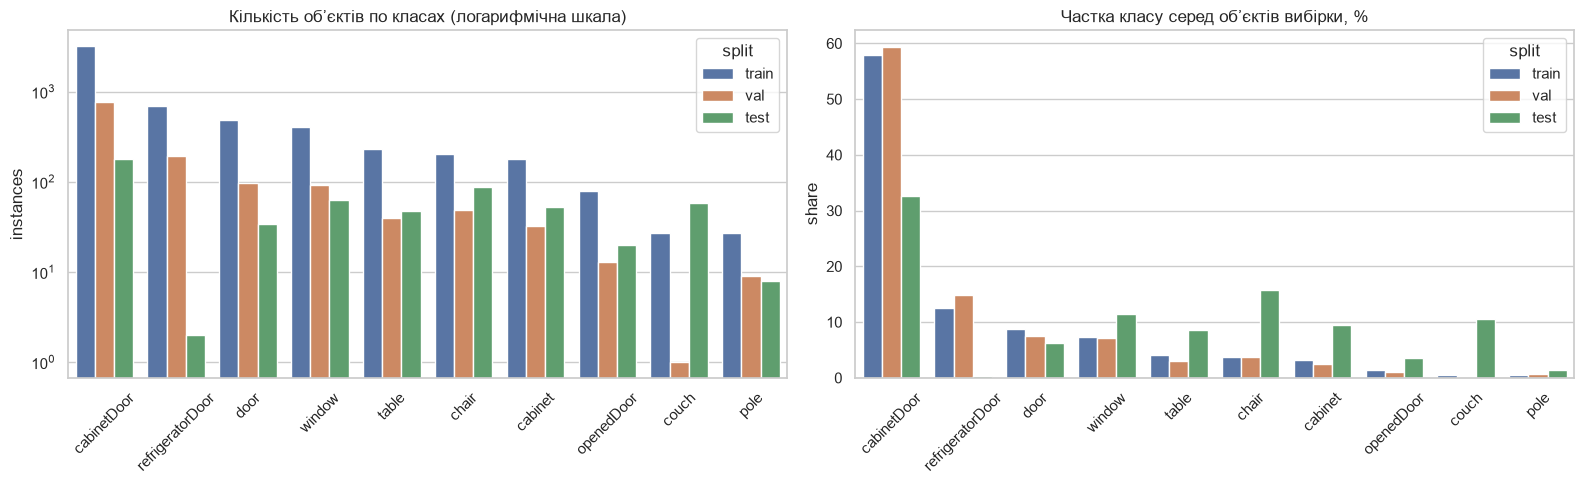

In [6]:
inst = (boxes_df.pivot_table(index='name', columns='split', values='cls', aggfunc='size', fill_value=0)
        .reindex(index=CLASS_NAMES, columns=SPLIT_ORDER))
imgs_with = (boxes_df.drop_duplicates(['split', 'file', 'name'])
             .pivot_table(index='name', columns='split', values='file', aggfunc='size', fill_value=0)
             .reindex(index=CLASS_NAMES, columns=SPLIT_ORDER))
class_table = pd.concat({'instances': inst, 'images with class': imgs_with}, axis=1)
class_table[('share', 'train %')] = 100 * inst['train'] / inst['train'].sum()
class_table[('share', 'test %')] = 100 * inst['test'] / inst['test'].sum()
class_table = class_table.sort_values(('instances', 'train'), ascending=False)
display(class_table)

imbalance = inst['train'].max() / inst['train'].min()
print(f'Дисбаланс у train: найчастіший клас {inst["train"].idxmax()} ({inst["train"].max()}) '
      f'vs найрідший {inst["train"].idxmin()} ({inst["train"].min()}) -> у {imbalance:.0f} разів')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
long = inst.reset_index().melt(id_vars='name', var_name='split', value_name='instances')
order = class_table.index.tolist()
sns.barplot(data=long, x='name', y='instances', hue='split', order=order, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Кількість обʼєктів по класах (логарифмічна шкала)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_xlabel('')
share = (inst / inst.sum() * 100).reset_index().melt(id_vars='name', var_name='split', value_name='share')
sns.barplot(data=share, x='name', y='share', hue='split', order=order, ax=axes[1])
axes[1].set_title('Частка класу серед обʼєктів вибірки, %')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

Класи сильно незбалансовані:
* `cabinetDoor` дає понад половину всіх обʼєктів train (це кухонні фасади, на одному фото їх десятки), далі йдуть `refrigeratorDoor`, `door`, `window`;
* `couch` і `pole` мають лише по 27 обʼєктів у train, `openedDoor` має 78, і на таких класах модель майже напевно буде гіршою;
* у valid `couch` представлений одним обʼєктом, тому метрика цього класу на val випадкова (0 або 1), і висновки про диван я робитиму за тестом;
* у test розподіл інший: там багато `chair`, `couch`, `cabinet`, `table` і майже немає `refrigeratorDoor` (2 обʼєкти). Тому середній mAP на test і на val не можна порівнювати «в лоб», бо ваги класів у середньому різні.

Найчастіші розміри зображень (ширина×висота, кількість):
  train: 1024×768 (262), 768×1024 (127), 1024×683 (80), 1024×1024 (47)
  val  : 1024×768 (56), 768×1024 (37), 1024×683 (22), 1024×1024 (15)
  test : 620×460 (107)

Розмір рамок у train (частка обʼєктів за розміром при imgsz=640, %; медіанна площа рамки, % площі кадру):


size_bucket,small (<32²),medium,large (>96²),median_rel_area_%,median_aspect_w/h
name,,,,,
cabinetDoor,14.164,63.708,22.128,1.197,1.053
refrigeratorDoor,1.161,23.657,75.181,6.977,0.496
door,1.674,29.707,68.619,6.793,0.336
window,12.903,54.839,32.258,1.669,0.561
table,0.877,24.123,75.000,7.505,1.866
chair,4.902,50.000,45.098,2.732,0.699
cabinet,1.117,12.849,86.034,15.057,0.993
openedDoor,0.000,12.821,87.179,10.173,0.435
couch,0.000,22.222,77.778,6.182,1.254


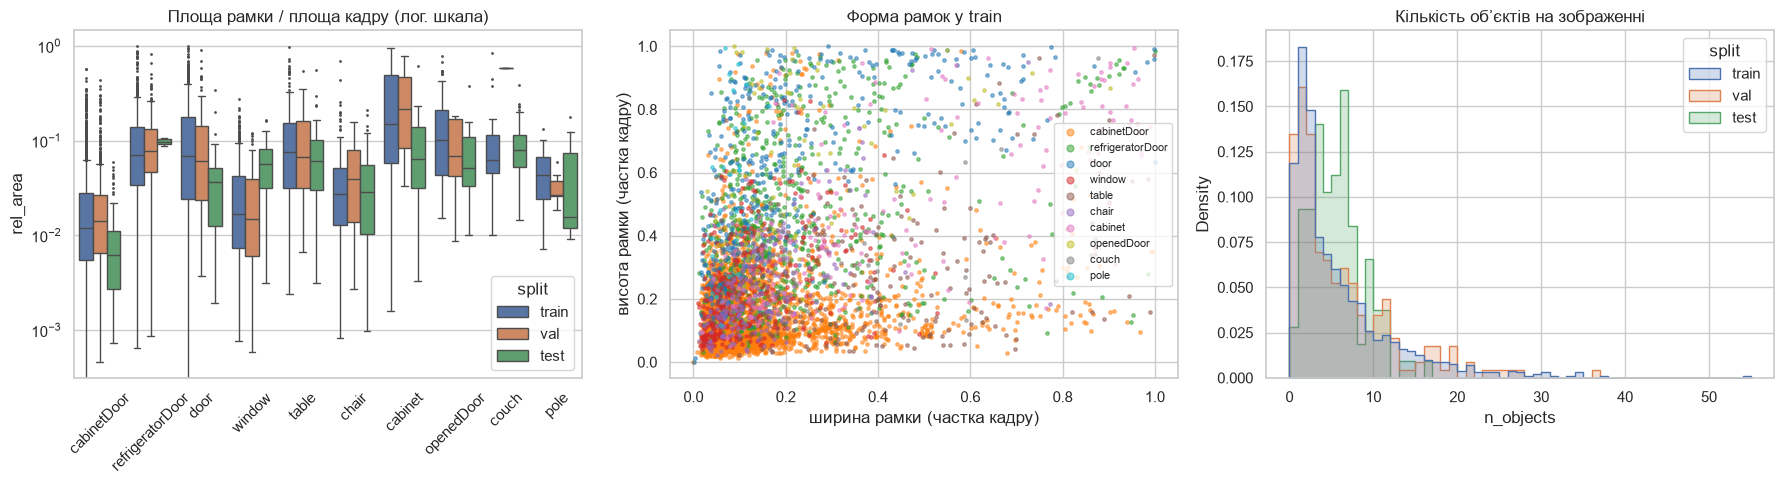

In [7]:
size_tbl = (images_df.assign(size=images_df['width'].astype(str) + '×' + images_df['height'].astype(str))
            .groupby('split')['size'].agg(lambda s: ', '.join(f'{k} ({v})' for k, v in Counter(s).most_common(4)))
            .reindex(SPLIT_ORDER))
print('Найчастіші розміри зображень (ширина×висота, кількість):')
for split, s in size_tbl.items():
    print(f'  {split:<5}: {s}')

# bounding-box geometry in pixels after the letterbox resize to the training size 640 (longer side = 640)
IMGSZ_EDA = 640
scale = IMGSZ_EDA / boxes_df[['img_w', 'img_h']].max(axis=1)
boxes_df['w_px'] = boxes_df['w'] * boxes_df['img_w'] * scale
boxes_df['h_px'] = boxes_df['h'] * boxes_df['img_h'] * scale
boxes_df['area_px'] = boxes_df['w_px'] * boxes_df['h_px']
boxes_df['rel_area'] = boxes_df['w'] * boxes_df['h']
boxes_df['aspect'] = boxes_df['w_px'] / boxes_df['h_px']
boxes_df['size_bucket'] = pd.cut(boxes_df['area_px'], [0, 32 ** 2, 96 ** 2, np.inf],
                                 labels=['small (<32²)', 'medium', 'large (>96²)'])

size_share = (pd.crosstab(boxes_df.loc[boxes_df.split == 'train', 'name'],
                          boxes_df.loc[boxes_df.split == 'train', 'size_bucket'], normalize='index') * 100)
size_share['median_rel_area_%'] = boxes_df[boxes_df.split == 'train'].groupby('name')['rel_area'].median() * 100
size_share['median_aspect_w/h'] = boxes_df[boxes_df.split == 'train'].groupby('name')['aspect'].median()
print('\nРозмір рамок у train (частка обʼєктів за розміром при imgsz=640, %; медіанна площа рамки, % площі кадру):')
display(size_share.reindex(order))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=boxes_df, x='name', y='rel_area', hue='split', order=order, ax=axes[0], fliersize=1)
axes[0].set_yscale('log')
axes[0].set_title('Площа рамки / площа кадру (лог. шкала)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_xlabel('')
tr = boxes_df[boxes_df.split == 'train']
for c in order:
    d = tr[tr.name == c]
    axes[1].scatter(d['w'], d['h'], s=6, alpha=0.5, color=PALETTE[c], label=c)
axes[1].set_xlabel('ширина рамки (частка кадру)')
axes[1].set_ylabel('висота рамки (частка кадру)')
axes[1].set_title('Форма рамок у train')
axes[1].legend(fontsize=8, markerscale=2)
sns.histplot(data=images_df, x='n_objects', hue='split', bins=range(0, images_df['n_objects'].max() + 2),
             stat='density', common_norm=False, element='step', ax=axes[2])
axes[2].set_title('Кількість обʼєктів на зображенні')
plt.tight_layout()
plt.show()

* Рамки `cabinetDoor` і `door` витягнуті вертикально. `cabinetDoor` часто дрібні (у кадрі багато фасадів), а `couch`, `table`, `cabinet`, `openedDoor` зазвичай займають велику частину кадру.
* Рамки `pole` тонкі й високі, з дуже малою площею. Для детектора це складна форма, бо по ширині мало пікселів.
* Кількість обʼєктів на зображенні дуже різна: від 0 до кількох десятків на кухонних фото.

Далі перевіряю дублікати (однакові за MD5 файли) всередині вибірок і між ними. Якщо те саме фото є і в train, і у val / test, метрики будуть завищені.

In [8]:
dup = images_df.groupby('md5').agg(n=('file', 'size'), splits=('split', lambda s: tuple(sorted(set(s)))))
dup = dup[dup['n'] > 1]
cross = dup[dup['splits'].map(len) > 1]
print(f'Груп однакових файлів: {len(dup)} (зображень у них: {int(dup["n"].sum())})')
print(f'З них між різними вибірками: {len(cross)}')
if len(cross):
    print(cross['splits'].value_counts().to_string())

Груп однакових файлів: 1 (зображень у них: 2)
З них між різними вибірками: 1
splits
(train, val)    1


Знайшлася лише одна пара однакових файлів (одне фото є і в train, і у valid). На метрики це майже не впливає, тому я нічого не видаляю. Масового витоку даних між вибірками немає.

Приклади зображень train з розміткою (колір рамки = клас):

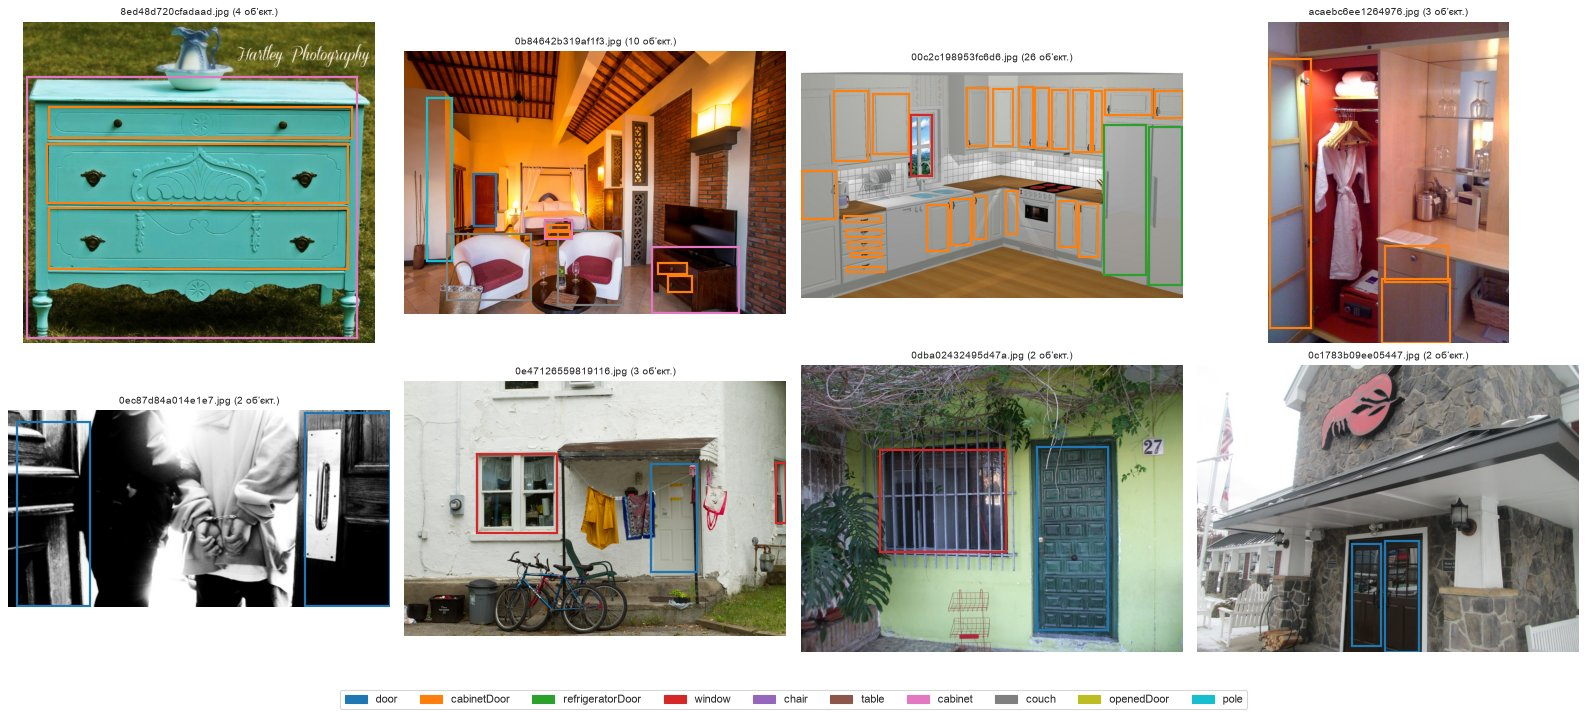

In [9]:
def draw_boxes(ax, boxes, W, H, lw=2, show_label=True, conf=None):
    """Draw YOLO-normalised boxes (cls, xc, yc, w, h) on a matplotlib axis."""
    for i, (c, xc, yc, bw, bh) in enumerate(boxes):
        name = CLASS_NAMES[int(c)]
        x0, y0 = (xc - bw / 2) * W, (yc - bh / 2) * H
        ax.add_patch(mpatches.Rectangle((x0, y0), bw * W, bh * H, fill=False, lw=lw, ec=PALETTE[name]))
        if show_label:
            txt = name if conf is None else f'{name} {conf[i]:.2f}'
            ax.text(x0, y0, txt, fontsize=7, color='white', va='bottom',
                    bbox=dict(facecolor=PALETTE[name], alpha=0.8, pad=1, lw=0))


def gt_boxes(split: str, file: str) -> np.ndarray:
    d = boxes_df[(boxes_df.split == split) & (boxes_df.file == file)]
    return d[['cls', 'xc', 'yc', 'w', 'h']].to_numpy()


def legend_handles(names=CLASS_NAMES):
    return [mpatches.Patch(color=PALETTE[n], label=n) for n in names]


rng = random.Random(SEED)
cand = images_df[(images_df.split == 'train') & (images_df.n_objects > 0)]
sample = cand.iloc[rng.sample(range(len(cand)), 8)]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB'))
    draw_boxes(ax, gt_boxes('train', r['file']), r['width'], r['height'], show_label=False)
    ax.set_title(f"{r['file'][:28]} ({r['n_objects']} обʼєкт.)", fontsize=9)
    ax.axis('off')
fig.legend(handles=legend_handles(), loc='lower center', ncol=NC, fontsize=10)
plt.tight_layout(rect=(0, 0.04, 1, 1))
show_jpeg(fig)

Це реальні фото кухонь, кімнат, коридорів і дверей з різних ракурсів. Уже тут видно особливості розмітки, які вплинуть на метрики:
* рамки вкладені одна в одну: `cabinet` (шафа цілком) містить кілька `cabinetDoor`, а `refrigeratorDoor` лежить усередині холодильника, тож та сама ділянка зображення належить до різних класів;
* `door` і `openedDoor` позначають той самий обʼєкт у різних станах, і межа між «прочиненими» й «зачиненими» дверима розмита.

## 4. YAML-конфігурація даних

Ultralytics читає опис датасету з YAML: корінь (`path`), відносні шляхи до зображень кожної вибірки (мітки шукаються автоматично в сусідній папці `labels/`), кількість класів `nc` і назви `names` у порядку індексів. Файл `data.yaml` створюю поруч із ноутбуком.

In [10]:
DATA_YAML = Path('data.yaml').resolve()
data_cfg = {
    'path': str(DATA_ROOT),
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': NC,
    'names': {i: n for i, n in enumerate(CLASS_NAMES)},
}
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True))
print(DATA_YAML)
print(DATA_YAML.read_text())

/Users/faridjafarli/GitHub/goit-hw/dl_computer_vision/hw03-indoor-object-detection/data.yaml
path: /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1
train: train/images
val: valid/images
test: test/images
nc: 10
names:
  0: door
  1: cabinetDoor
  2: refrigeratorDoor
  3: window
  4: chair
  5: table
  6: cabinet
  7: couch
  8: openedDoor
  9: pole



## 5. Вибір архітектури: YOLOv9s

Я обрав одноетапний детектор YOLO. Двоетапні детектори (Faster R-CNN) точні, але повільніші й складніші в навчанні. Для задачі «робот / застосунок бачить меблі й двері в кімнаті» важлива швидкість, а сучасні одноетапні YOLO на COCO за точністю вже не поступаються Faster R-CNN. Ultralytics дає готовий пайплайн (аугментації, TAL-призначення міток, EMA ваг, mAP-валідацію), тому можна зосередитися на даних і аналізі.

Серед версій YOLO я взяв YOLOv9s, яку рекомендує умова. Причини такі:
* Модель мала: ≈ 7.2 млн параметрів, ≈ 27 GFLOPs. Для ~1 тис. навчальних зображень більша модель швидше перенавчиться і довше навчатиметься.
* Backbone / neck побудовані на GELAN (блоки `RepNCSPELAN4`, `AConv`, `SPPELAN`), де поєднано ідеї CSP та ELAN: багато шляхів градієнта при малій кількості параметрів. У статті YOLOv9 модель s досягає ≈ 46.8 % mAP50-95 на COCO. Це більше, ніж у YOLOv8s (44.9 %), і параметрів при цьому менше.
* Голова Detect anchor-free і декаплована (окремі гілки класифікації й регресії рамки), вона працює на трьох масштабах (stride 8 / 16 / 32). Це потрібно, бо в датасеті є і дрібні фасади, і диван на весь кадр.
* Функція втрат має складові, які потім буде видно на кривих навчання: box loss рахується як CIoU (перекриття, відстань центрів і співвідношення сторін рамок), cls loss як BCE (незалежна бінарна крос-ентропія на кожен клас), а DFL (Distribution Focal Loss) передбачає рамку як розподіл відстаней до сторін. Окремої objectness-гілки, як у YOLOv3-v5, у YOLOv8 / v9 немає.
* Ваги претреновані на COCO, а там уже є `chair`, `couch`, `dining table`, `refrigerator`, тож ознаки меблів моделі частково «знайомі».

У цього вибору є недоліки й ризики. Мала модель має обмежену «ємність» для 10 візуально схожих класів (різні двері й дверцята). У реалізації Ultralytics для v9s немає допоміжної гілки PGI: у структурі моделі у виводі навчання є лише GELAN-блоки та Detect, тобто навчається просто GELAN-мережа. Фіксований вхід 640 px зменшує дрібні обʼєкти (фасади, тонкі стовпи). Альтернативи: YOLOv9m / YOLO11m (більша ємність), RT-DETR (трансформерний детектор, краще працює з контекстом, але потребує більше даних і часу), Faster R-CNN + FPN (точніше локалізує дрібні обʼєкти, але повільніший).

Спершу перевіряю, що бачить претренована на COCO модель без донавчання, як у практиці теми 7.

yolov9s: 7.32 млн параметрів, класів COCO: 80
Претренована COCO-модель знайшла: {'couch': 3, 'chair': 5, 'book': 2, 'remote': 2, 'potted plant': 1}
Розмітка датасету на цьому фото: {'cabinetDoor': 6, 'chair': 3, 'couch': 3, 'table': 2, 'door': 1, 'cabinet': 1}


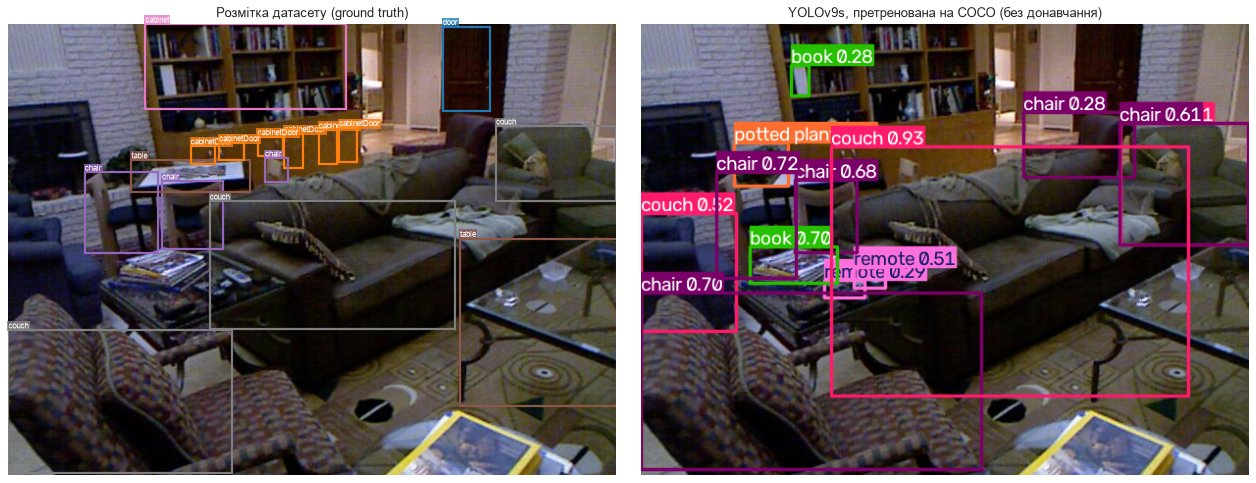

In [11]:
BASE_MODEL = 'yolov9s'
base_model = YOLO(f'{BASE_MODEL}.pt')     # COCO-pretrained weights (downloaded automatically on first use)
n_params = sum(p.numel() for p in base_model.model.parameters())
print(f'{BASE_MODEL}: {n_params / 1e6:.2f} млн параметрів, класів COCO: {len(base_model.names)}')

# a test image that contains furniture from both COCO and our label set
test_sets = boxes_df[boxes_df.split == 'test'].groupby('file')['name'].agg(set)
with_furniture = test_sets[test_sets.map(lambda x: {'couch', 'chair'} <= x)]
demo = with_furniture.index[0] if len(with_furniture) else test_sets.map(len).idxmax()
demo_path = DATA_ROOT / 'test' / 'images' / demo
res = base_model.predict(demo_path, conf=0.25, device=EVAL_DEVICE, verbose=False)[0]
coco_found = Counter(res.names[int(c)] for c in res.boxes.cls)
print('Претренована COCO-модель знайшла:', dict(coco_found))
print('Розмітка датасету на цьому фото:', dict(Counter(boxes_df[(boxes_df.split == 'test') & (boxes_df.file == demo)]['name'])))

W, H = Image.open(demo_path).size
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(Image.open(demo_path).convert('RGB'))
draw_boxes(axes[0], gt_boxes('test', demo), W, H)
axes[0].set_title('Розмітка датасету (ground truth)')
axes[1].imshow(res.plot()[..., ::-1])   # res.plot() returns BGR
axes[1].set_title('YOLOv9s, претренована на COCO (без донавчання)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
show_jpeg(fig)

Претренована модель знаходить стільці й дивани (плюс «зайві» для нас книжки, пульти, вазон), але не бачить ні дверцят шафи, ні дверей, ні шафи, а столи на цьому кадрі взагалі пропускає. Серед 80 класів COCO немає дверей, вікон, дверцят і колон, а `dining table` / `refrigerator` описують обʼєкт інакше, ніж розмітка датасету (цілий холодильник vs його дверцята). З кріслами теж є розбіжність: COCO-модель називає їх `chair`, а в розмітці датасету крісло позначене як `couch`. Тому модель треба донавчити (fine-tuning) на нашому датасеті з новою головою на 10 класів, а backbone і neck стартують з COCO-ваг.

## 6. Навчання YOLOv9s

Гіперпараметри близькі до практики теми 7, я лише підібрав їх під доступний час і розмір датасету:

| Параметр | Значення | Пояснення |
|---|---|---|
| `epochs` / `patience` | 60 / 20 | у пробному запуску одна епоха на MPS тривала ≈ 1-1.3 хв, тож 60 епох вкладаються в ≈ 1-1.5 год; якщо mAP50-95 на val не росте 20 епох, спрацьовує рання зупинка |
| `imgsz` | 640 | стандартний розмір для YOLO (зображення ≈ 1024×768 зменшуються з letterbox) |
| `batch` | 16 | вміщується в памʼять GPU (≈ 11 ГБ на MPS) |
| `optimizer` | `auto` | для коротких запусків (< 10 тис. ітерацій) Ultralytics обирає AdamW і сам підбирає lr (див. рядок `optimizer:` у виводі) |
| `close_mosaic` | 10 | останні 10 епох без mosaic-аугментації, щоб модель «звикла» до звичайних кадрів |
| `cache` | `ram` | зменшені зображення кешуються в памʼяті; на MPS / CPU Ultralytics вантажить дані в основному процесі, і без кешу декодування JPEG гальмує епоху |
| аугментації | стандартні | mosaic, HSV-зсуви кольору, масштаб ±50 %, зсув ±10 %, горизонтальний фліп 0.5, random erasing |
| `seed` | 42 | відтворюваність (наскільки дозволяє GPU); `deterministic=False`, бо на MPS частина операцій не має детермінованої реалізації |

Після кожної епохи Ultralytics рахує на valid P, R, mAP50, mAP50-95 і зберігає `last.pt` та `best.pt` (найкраща епоха за mAP50-95). Після навчання я копіюю `best.pt` у `weights/best.pt`.

In [12]:
class CFG:
    BASE_MODEL = BASE_MODEL
    EPOCHS = 60
    PATIENCE = 20
    IMGSZ = 640
    BATCH = 16
    OPTIMIZER = 'auto'
    CLOSE_MOSAIC = 10
    CACHE = 'ram'
    WORKERS = 4          # used on CUDA; Ultralytics forces 0 dataloader workers on MPS / CPU
    FRACTION = 1.0       # share of the train set to use (1.0 = all images)
    PROJECT = Path('runs').resolve()
    NAME = f'{BASE_MODEL}_indoor'
    WEIGHTS_DIR = Path('weights')

Я навчав модель на спільному Mac, де GPU одночасно на ~100 % навантажували інші процеси. У такому режимі macOS примусово перериває частину GPU-команд (у логах Metal: `kIOGPUCommandBufferCallbackErrorImpactingInteractivity`). Після цього MPS-операції `nonzero()` / індексація булевою маскою повертають «сміття», а після кількох збоїв система взагалі перестає приймати GPU-команди від цього процесу (`kIOGPUCommandBufferCallbackErrorSubmissionsIgnored`). Я відтворив це окремим стрес-тестом поза Ultralytics. При зайнятому GPU кілька відсотків викликів `nonzero()` давали неправильну кількість або неможливі індекси, а з `torch.mps.synchronize()` перед викликом не було жодного такого випадку. Під час перших спроб навчання в процесі ноутбука це виглядало як аварійна зупинка посеред епохи: `RuntimeError: numel: integer multiplication overflow`, `AcceleratorError: index 4432936322480860963 is out of bounds for dimension 0 with size 16`, `RuntimeError: num_unique >= 1 INTERNAL ASSERT FAILED ... Unique.mm`. Отже, проблема в стані GPU, а не в даних чи коді.

Тому навчання запускається через CLI Ultralytics в окремому процесі (`entrypoint()` з `ultralytics.cfg`, те саме, що `!yolo detect train ...`; вивід транслюється сюди). Якщо на MPS процес падає з GPU-помилкою, новий процес продовжує навчання з останнього чекпойнта `last.pt` штатним механізмом `resume`. Відновлюються ваги, EMA, стан оптимізатора й номер епохи, втрачається лише незавершена епоха. Якщо збій стався до першого чекпойнта, навчання починається заново. Кожен перезапуск друкується у виводі й потрапляє в підсумкову таблицю. На CUDA / CPU будь-яка помилка просто зупиняє клітинку. Якщо навчання йде на MPS, оцінку моделі (розділи 8-12) я виконую на CPU (`EVAL_DEVICE`).

Фінальний запуск нижче я стартував, коли інші задачі звільнили GPU, тож перезапусків не знадобилося (див. рядок «Перезапусків після збою MPS: 0»).

In [13]:
print(f'Модель: {CFG.BASE_MODEL}.pt | епох: {CFG.EPOCHS} (patience {CFG.PATIENCE}) | imgsz: {CFG.IMGSZ} | '
      f'batch: {CFG.BATCH} | пристрій: {DEVICE_NAME}')

RUN_DIR = CFG.PROJECT / CFG.NAME
LAST_PT = RUN_DIR / 'weights' / 'last.pt'
MAX_RESTARTS = 30
ANSI = re.compile(r'\x1b\[[0-9;]*[A-Za-z]')

train_args = dict(
    data=DATA_YAML,
    epochs=CFG.EPOCHS,
    patience=CFG.PATIENCE,
    imgsz=CFG.IMGSZ,
    batch=CFG.BATCH,
    optimizer=CFG.OPTIMIZER,
    close_mosaic=CFG.CLOSE_MOSAIC,
    cache=CFG.CACHE,
    workers=CFG.WORKERS,
    fraction=CFG.FRACTION,
    device=DEVICE,
    seed=SEED,
    deterministic=False,
    project=CFG.PROJECT,
    name=CFG.NAME,
    exist_ok=True,
    plots=True,
    verbose=True,
)
YOLO_CLI = [sys.executable, '-c', 'from ultralytics.cfg import entrypoint; entrypoint()', 'detect', 'train']  # == `yolo detect train`
FRESH_CMD = YOLO_CLI + [f'model={CFG.BASE_MODEL}.pt'] + [f'{k}={v}' for k, v in train_args.items()]
RESUME_CMD = YOLO_CLI + ['resume', f'model={LAST_PT}']


def run_streaming(cmd):
    # run a command, stream its output into the notebook; return (exit code, tail of the output without colours)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            env={**os.environ, 'PYTHONUNBUFFERED': '1'})
    decoder = codecs.getincrementaldecoder('utf-8')(errors='replace')
    tail = ''
    for chunk in iter(lambda: proc.stdout.read1(1 << 16), b''):
        text = decoder.decode(chunk)
        sys.stdout.write(text)
        tail = (tail + text)[-5000:]
    sys.stdout.flush()
    return proc.wait(), ANSI.sub('', tail)


def epochs_done() -> int:
    csv = RUN_DIR / 'results.csv'
    return len(pd.read_csv(csv)) if csv.exists() else 0


print('Команда навчання: yolo', ' '.join(str(c) for c in FRESH_CMD[3:]), '\n', flush=True)
shutil.rmtree(RUN_DIR, ignore_errors=True)               # artefacts of a previous execution of this notebook
restarts = []
t0 = time.time()
while True:
    code, tail = run_streaming(RESUME_CMD if LAST_PT.exists() else FRESH_CMD)
    if code == 0 or 'nothing to resume' in tail:         # finished (a crash after the last epoch leaves nothing to resume)
        break
    lines = [l.strip() for l in tail.splitlines() if l.strip()]
    err = next((l for l in reversed(lines) if 'Error' in l), lines[-1] if lines else f'exit code {code}')
    restarts.append({'завершених епох до збою': epochs_done(), 'помилка': err[:110]})
    gpu_failure = code < 0 or re.search(r'AcceleratorError|RuntimeError|MPS|Metal|command buffer', tail)
    if DEVICE != 'mps' or not gpu_failure or len(restarts) >= MAX_RESTARTS:
        raise RuntimeError(f'Навчання зупинилося з кодом {code}: {err}')
    action = f'resume з {LAST_PT.name}' if LAST_PT.exists() else 'з нуля'
    print(f'\n>>> Збій MPS після {epochs_done()} завершених епох: {err[:110]}\n>>> Перезапуск у новому процесі ({action})\n',
          flush=True)
    time.sleep(10)
TRAIN_MINUTES = (time.time() - t0) / 60

CFG.WEIGHTS_DIR.mkdir(exist_ok=True)
BEST_WEIGHTS = CFG.WEIGHTS_DIR / 'best.pt'
shutil.copy2(RUN_DIR / 'weights' / 'best.pt', BEST_WEIGHTS)
print(f'\nЧас навчання: {TRAIN_MINUTES:.1f} хв на {DEVICE_NAME}; завершених епох: {epochs_done()}')
print(f'Перезапусків після збою MPS: {len(restarts)}')
if restarts:
    display(pd.DataFrame(restarts))
print(f'Результати навчання: {RUN_DIR}')
print(f'Найкращі ваги збережено: {BEST_WEIGHTS.resolve()} ({BEST_WEIGHTS.stat().st_size / 1e6:.1f} МБ)')

Модель: yolov9s.pt | епох: 60 (patience 20) | imgsz: 640 | batch: 16 | пристрій: MPS: Apple M2 Max GPU
Команда навчання: yolo detect train model=yolov9s.pt data=/Users/faridjafarli/GitHub/goit-hw/dl_computer_vision/hw03-indoor-object-detection/data.yaml epochs=60 patience=20 imgsz=640 batch=16 optimizer=auto close_mosaic=10 cache=ram workers=4 fraction=1.0 device=mps seed=42 deterministic=False project=/Users/faridjafarli/GitHub/goit-hw/dl_computer_vision/hw03-indoor-object-detection/runs name=yolov9s_indoor exist_ok=True plots=True verbose=True 

Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 MPS (Apple M2 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/faridjafarli/GitHub/goit-hw/dl_computer_v

## 7. Криві навчання

Ultralytics записує метрики кожної епохи в `results.csv`. Будую криві train vs val для трьох складових втрат і динаміку P / R / mAP на valid. Вертикальна лінія позначає найкращу епоху (max mAP50-95 на val, саме її ваги збережено в `best.pt`), пунктир позначає вимкнення mosaic (останні `close_mosaic` епох).

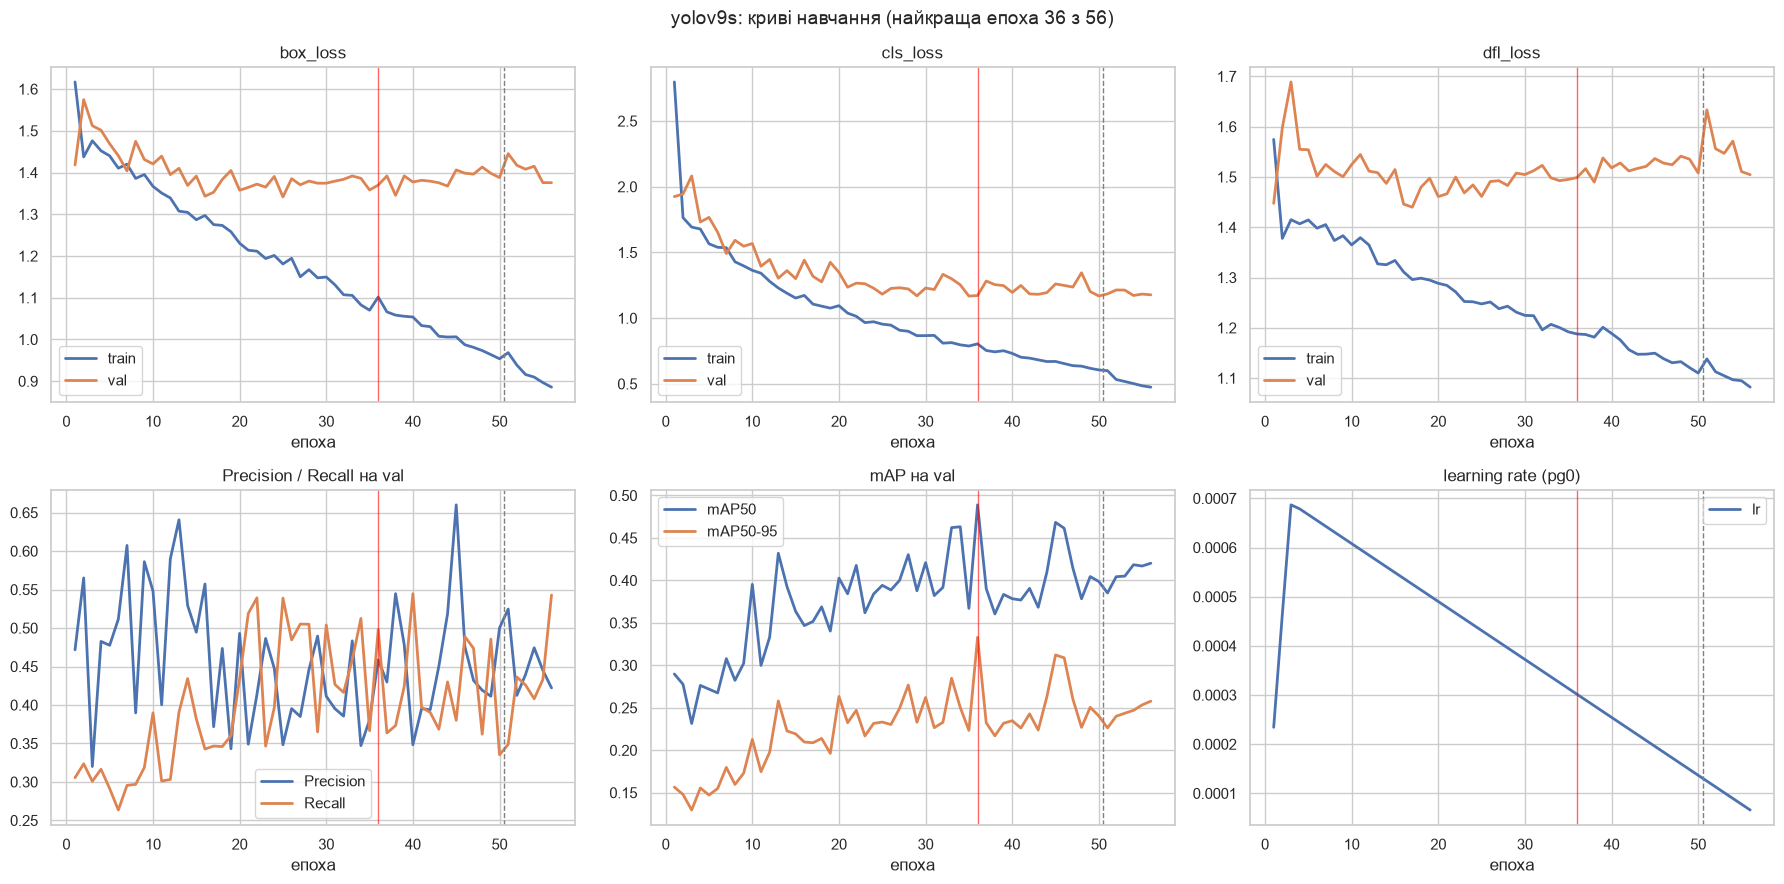

,train/box_loss,val/box_loss,train/cls_loss,val/cls_loss,train/dfl_loss,val/dfl_loss,P,R,mAP50,mAP50-95
epoch,,,,,,,,,,
1,1.617,1.418,2.797,1.925,1.575,1.447,0.472,0.305,0.290,0.157
5,1.440,1.469,1.566,1.767,1.414,1.554,0.478,0.291,0.272,0.147
10,1.367,1.421,1.364,1.568,1.365,1.525,0.548,0.390,0.395,0.213
20,1.231,1.358,1.095,1.349,1.288,1.461,0.493,0.434,0.403,0.263
30,1.150,1.374,0.867,1.229,1.225,1.505,0.411,0.504,0.421,0.262
36,1.102,1.370,0.804,1.172,1.188,1.499,0.459,0.498,0.489,0.333
40,1.054,1.377,0.731,1.195,1.189,1.518,0.348,0.545,0.378,0.235
50,0.954,1.388,0.606,1.168,1.110,1.508,0.500,0.335,0.399,0.240
56,0.886,1.376,0.475,1.177,1.082,1.504,0.422,0.543,0.420,0.258


Мінімум сумарного val loss — епоха 25; максимум mAP50 — епоха 36; максимум mAP50-95 — епоха 36
Епох виконано: 56 із 60 (рання зупинка)


In [14]:
hist = pd.read_csv(RUN_DIR / 'results.csv')
hist.columns = hist.columns.str.strip()
hist = hist.drop_duplicates('epoch', keep='last').reset_index(drop=True)   # safety after a resume
hist = hist.rename(columns={'metrics/precision(B)': 'P', 'metrics/recall(B)': 'R',
                            'metrics/mAP50(B)': 'mAP50', 'metrics/mAP50-95(B)': 'mAP50-95'})
best_idx = hist['mAP50-95'].idxmax()
BEST_EPOCH = int(hist.loc[best_idx, 'epoch'])
N_EPOCHS_RUN = int(hist['epoch'].max())
mosaic_off = CFG.EPOCHS - CFG.CLOSE_MOSAIC + 0.5

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, loss in zip(axes[0], ['box_loss', 'cls_loss', 'dfl_loss']):
    ax.plot(hist['epoch'], hist[f'train/{loss}'], label='train', lw=2)
    ax.plot(hist['epoch'], hist[f'val/{loss}'], label='val', lw=2)
    ax.set_title(loss)
    ax.set_xlabel('епоха')
axes[1, 0].plot(hist['epoch'], hist['P'], label='Precision', lw=2)
axes[1, 0].plot(hist['epoch'], hist['R'], label='Recall', lw=2)
axes[1, 0].set_title('Precision / Recall на val')
axes[1, 1].plot(hist['epoch'], hist['mAP50'], label='mAP50', lw=2)
axes[1, 1].plot(hist['epoch'], hist['mAP50-95'], label='mAP50-95', lw=2)
axes[1, 1].set_title('mAP на val')
axes[1, 2].plot(hist['epoch'], hist['lr/pg0'], lw=2, label='lr')
axes[1, 2].set_title('learning rate (pg0)')
for ax in axes.ravel():
    ax.axvline(BEST_EPOCH, color='red', ls='-', lw=1, alpha=0.6)
    if mosaic_off < N_EPOCHS_RUN:
        ax.axvline(mosaic_off, color='gray', ls='--', lw=1)
    ax.set_xlabel('епоха')
    ax.legend()
plt.suptitle(f'{CFG.BASE_MODEL}: криві навчання (найкраща епоха {BEST_EPOCH} з {N_EPOCHS_RUN})', fontsize=14)
plt.tight_layout()
plt.show()

cols = ['epoch', 'train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss', 'train/dfl_loss',
        'val/dfl_loss', 'P', 'R', 'mAP50', 'mAP50-95']
key_epochs = sorted({1, 5, 10, 20, 30, 40, 50, BEST_EPOCH, N_EPOCHS_RUN} & set(hist['epoch']))
display(hist.set_index('epoch').loc[key_epochs, cols[1:]])

val_loss_sum = hist[['val/box_loss', 'val/cls_loss', 'val/dfl_loss']].sum(axis=1)
print(f'Мінімум сумарного val loss — епоха {int(hist.loc[val_loss_sum.idxmin(), "epoch"])}; '
      f'максимум mAP50 — епоха {int(hist.loc[hist["mAP50"].idxmax(), "epoch"])}; '
      f'максимум mAP50-95 — епоха {BEST_EPOCH}')
print(f'Епох виконано: {N_EPOCHS_RUN} із {CFG.EPOCHS}' + (' (рання зупинка)' if N_EPOCHS_RUN < CFG.EPOCHS else ''))

Аналіз кривих навчання:

* Навчання зупинилося ранньою зупинкою на 56-й епосі з 60. Найкращий mAP50-95 на val (0.333) був на 36-й епосі, і 20 епох поспіль кращого результату не було. У `best.pt` збережено саме ваги 36-ї епохи.
* Втрати на train спадають увесь час: box 1.62 → 0.89, cls 2.80 → 0.48, dfl 1.58 → 1.08 (1-ша → 56-та епоха). Недонавчання немає, модель добре підлаштовується під навчальні дані.
* Втрати на val поводяться інакше: box loss після ~10-ї епохи тримається на рівні ≈ 1.35-1.45, dfl на рівні ≈ 1.45-1.55 і до кінця навіть трохи росте, а cls loss спадає до ≈ 1.17 приблизно до 35-ї епохи і далі не змінюється. Мінімум сумарного val loss припадає на 25-ту епоху.
* Отже, після ~25-35 епох починається перенавчання. Розрив між train і val збільшується (train cls loss 0.80 на 36-й епосі → 0.48 на 56-й, а val cls loss не змінюється), mAP на val не росте. Додаткові епохи самі по собі не допоможуть, бо модель обмежують дані (мало прикладів рідкісних класів).
* Після вимкнення mosaic на останніх 10 епохах (з 51-ї, пунктир) train loss різко знизився, бо звичайні кадри «легші» за мозаїку. mAP на val від цього не піднявся (mAP50-95 ≈ 0.23-0.26).
* Метрики на val дуже «шумні»: mAP50-95 між сусідніми епохами стрибає на 0.05-0.1 (35-та епоха 0.223, 36-та 0.333, 37-ма 0.232). Причина в маленькому val (230 фото, 60 % обʼєктів у ньому `cabinetDoor`) і в класах з кількома обʼєктами, AP яких від однієї-двох рамок змінюється між 0 і 1 (`couch` у val має один обʼєкт). Через це значення найкращої епохи трохи оптимістичне (епоху обрано саме за val), а незалежну оцінку дає test.
* P і R ходять «у протифазі», бо Ultralytics показує їх при порозі confidence, де середній F1 максимальний, а цей поріг від епохи до епохи зміщується. mAP від порогу не залежить, тому стежити варто саме за ним.
* lr: 3 епохи warmup до ≈ 7·10⁻⁴ (AdamW, який обрав `optimizer=auto`), далі лінійне спадання.

## 8. Оцінка на валідаційній вибірці

Повторно валідую збережені ваги `weights/best.pt` на valid (`split='val'`) зі стандартними порогами Ultralytics: `conf=0.001`, NMS IoU 0.7. Саме так рахується mAP. Метрики:
* mAP50: середня по класах AP при IoU ≥ 0.5 (площа під PR-кривою класу);
* mAP50-95: середнє mAP за порогами IoU 0.50, 0.55, …, 0.95 (метрика COCO, вимагає точної локалізації);
* Precision / Recall: Ultralytics наводить їх при одному порозі confidence, де середній по класах F1 максимальний;
* F1 = 2·P·R / (P + R) по кожному класу.

In [15]:
best_model = YOLO(BEST_WEIGHTS)
# on CPU: batch 1, because Ultralytics limits NMS time per batch (2 s + 0.05 s * batch); with batch 1 every image
# gets ~2 s and no predictions are dropped even on a busy CPU
EVAL_BATCH = 1 if EVAL_DEVICE == 'cpu' else CFG.BATCH


def evaluate(split: str):
    return best_model.val(data=str(DATA_YAML), split=split, imgsz=CFG.IMGSZ, batch=EVAL_BATCH, device=EVAL_DEVICE,
                          plots=True, project=str(CFG.PROJECT), name=f'eval_{split}', exist_ok=True, verbose=True)


def per_class_table(metrics) -> pd.DataFrame:
    box = metrics.box
    idx = list(box.ap_class_index)
    df = pd.DataFrame({
        'class': [CLASS_NAMES[i] for i in idx],
        'images': [int(metrics.nt_per_image[i]) for i in idx],
        'instances': [int(metrics.nt_per_class[i]) for i in idx],
        'P': box.p, 'R': box.r,
        'mAP50': box.ap50, 'mAP50-95': box.ap,
    })
    df['F1'] = 2 * df['P'] * df['R'] / (df['P'] + df['R']).replace(0, np.nan)
    df['F1'] = df['F1'].fillna(0.0)
    return df.set_index('class')[['images', 'instances', 'P', 'R', 'F1', 'mAP50', 'mAP50-95']]


def overall(metrics, per_class: pd.DataFrame) -> dict:
    box = metrics.box
    conf_grid = np.linspace(0, 1, len(box.f1_curve.mean(0)))
    return {'P': box.mp, 'R': box.mr, 'mAP50': box.map50, 'mAP50-95': box.map,
            'F1 (середнє по класах)': per_class['F1'].mean(),
            'conf при max F1': float(conf_grid[box.f1_curve.mean(0).argmax()])}


val_metrics = evaluate('val')
val_pc = per_class_table(val_metrics)
VAL = overall(val_metrics, val_pc)
VAL_DIR = Path(val_metrics.save_dir)

Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 CPU (Apple M2 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4377.2±1371.1 MB/s, size: 272.4 KB)
val: Scanning /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/valid/labels.cache... 230 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 107.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 230/230 9.5it/s 24.1s
                   all        230       1289      0.428      0.511      0.495      0.336
                  door         63         97      0.424      0.619      0.542      0.341
           cabinetDoor         99        765      0.717      0.799      0.794      0.443
      refrigeratorDoor         85        192      0.681      0.778      0.771      0.519
                window         39         91      0.367      0.429 

**Загальні метрики на valid**

,P,R,mAP50,mAP50-95,F1 (середнє по класах),conf при max F1
valid,0.428,0.511,0.495,0.336,0.432,0.188


**Метрики по класах на valid (відсортовано за F1)**

,images,instances,P,R,F1,mAP50,mAP50-95
class,,,,,,,
cabinetDoor,99,765,0.717,0.799,0.755,0.794,0.443
refrigeratorDoor,85,192,0.681,0.778,0.726,0.771,0.519
chair,24,49,0.499,0.592,0.542,0.580,0.325
door,63,97,0.424,0.619,0.503,0.542,0.341
cabinet,28,32,0.434,0.406,0.420,0.417,0.286
window,39,91,0.367,0.429,0.396,0.344,0.217
couch,1,1,0.225,1.000,0.367,0.995,0.995
table,30,40,0.364,0.300,0.329,0.240,0.117
pole,4,9,0.350,0.111,0.169,0.147,0.052


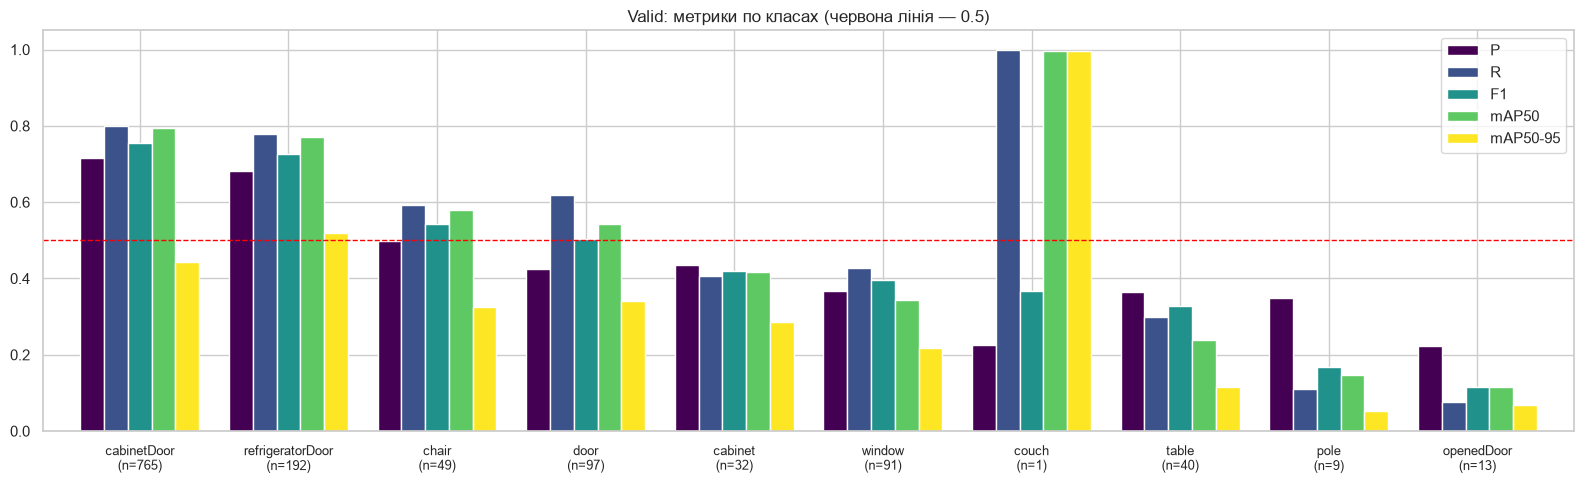

In [16]:
title('Загальні метрики на valid')
display(pd.Series(VAL, name='valid').to_frame().T)

title('Метрики по класах на valid (відсортовано за F1)')
display(val_pc.sort_values('F1', ascending=False).style.format(
    {'P': '{:.3f}', 'R': '{:.3f}', 'F1': '{:.3f}', 'mAP50': '{:.3f}', 'mAP50-95': '{:.3f}'})
    .background_gradient(subset=['P', 'R', 'F1', 'mAP50', 'mAP50-95'], cmap='RdYlGn', vmin=0, vmax=1))

plot_df = val_pc.sort_values('F1', ascending=False)[['P', 'R', 'F1', 'mAP50', 'mAP50-95']]
ax = plot_df.plot(kind='bar', figsize=(16, 5), width=0.8, colormap='viridis')
ax.axhline(0.5, color='red', ls='--', lw=1)
ax.set_title('Valid: метрики по класах (червона лінія — 0.5)')
ax.set_ylim(0, 1.05)
ax.set_xlabel('')
ax.set_xticklabels([f'{c}\n(n={val_pc.loc[c, "instances"]})' for c in plot_df.index], rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

Орієнтовні значення з умови: mAP50 40-60 %, mAP50-95 25-40 %, P по класах 40-75 %, R 50-70 %, F1 45-60 %.

Загалом на valid: P = 0.428, R = 0.511, mAP50 = 0.495, mAP50-95 = 0.336, середній F1 = 0.432 (поріг confidence з максимальним середнім F1 ≈ 0.19). mAP50 49.5 % і mAP50-95 33.6 % потрапляють в орієнтири з умови (40-60 % і 25-40 %). Ultralytics у кінці навчання на MPS показав майже ті самі числа (0.489 / 0.333). Невелика різниця виникає через інший пристрій і batch при валідації (1 на CPU, 16 на MPS), бо від batch залежить доповнення letterbox у rect-батчах. Отже, GPU-збої на фінальний запуск не вплинули.

Найкращі класи за F1: `cabinetDoor` (F1 0.755; P 0.72, R 0.80, mAP50 0.79), `refrigeratorDoor` (0.726; 0.68 / 0.78 / 0.77), `chair` (0.542; 0.50 / 0.59 / 0.58), `door` (0.503; 0.42 / 0.62 / 0.54). Три з них є найчисленнішими класами train (3178, 689 і 479 обʼєктів). `chair` має лише 204 обʼєкти, але виграє від претренування: стілець є в COCO, і Ultralytics навіть скопіював для нього (і для `couch`) рядок класифікаційної голови з COCO-ваг (`Remapped 2/10 cls head rows ... by class name` у виводі навчання).

Посередині опинилися `cabinet` 0.420, `window` 0.396, `table` 0.329. Найгірші `openedDoor` (F1 0.115; R 0.08, знайдено 1 з 13) і `pole` (0.169; R 0.11, 1 з 9). `couch` у valid має один обʼєкт, тому mAP50 0.995 і F1 0.367 нічого не означають. Реальну якість для дивана показує test.

Тепер по класах проти орієнтирів. Precision для «простих» дверей і вікон (60-75 %) у мене нижча: `door` 0.42, `window` 0.37. Зате `cabinetDoor` (0.72) і `refrigeratorDoor` (0.68) у діапазоні, хоча умова відносить дверцята шафи до найскладніших (у цьому датасеті їх просто дуже багато). `chair` з 0.50 потрапляє в діапазон 50-65 %, `table` з 0.36 нижче. `openedDoor` з 0.22 нижче за 40-55 %. Recall 50-70 % або вищий мають `cabinetDoor`, `refrigeratorDoor`, `door`, `chair`, нижчий мають `window`, `cabinet`, `table`, `pole`, `openedDoor`. Середній F1 0.43 трохи не дотягує до 45-60 % через три майже не вивчені рідкісні класи.

PR-криві (площа під кривою класу = AP50) та залежність F1 від порогу confidence, які Ultralytics зберіг під час валідації:

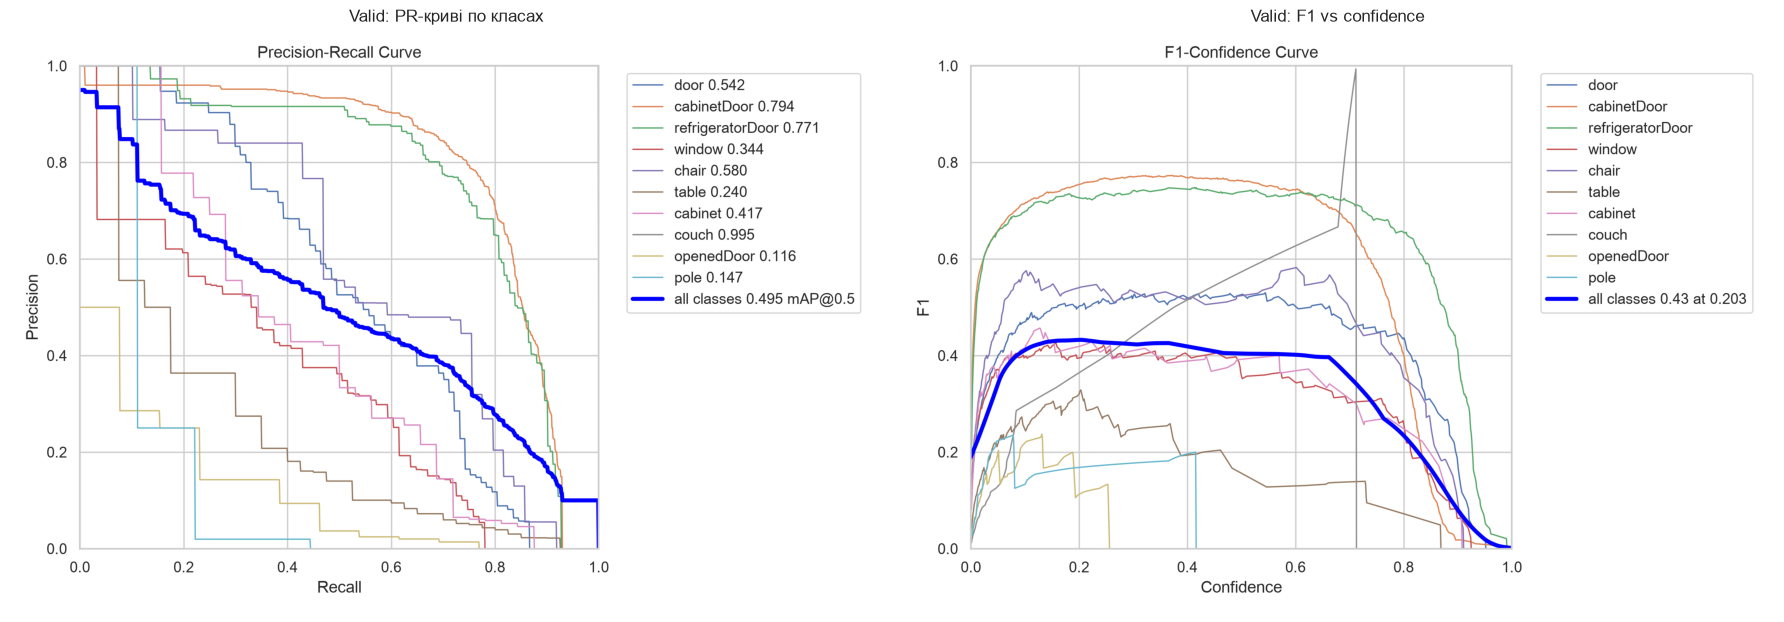

In [17]:
def show_images(paths, titles=None, ncols=2, width=9):
    paths = [Path(p) for p in paths]
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, width * 0.7 * nrows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis('off')
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles or [p.name for p in paths]):
        ax.imshow(plt.imread(p))
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


curve_files = [next(VAL_DIR.glob('*PR_curve.png')), next(VAL_DIR.glob('*F1_curve.png'))]
show_images(curve_files, ['Valid: PR-криві по класах', 'Valid: F1 vs confidence'])

## 9. Матриця помилок (confusion matrix)

Ultralytics будує матрицю при `conf ≥ 0.25` і IoU ≥ 0.45. Кожна рамка ground truth або зіставляється з передбаченням (правильного чи іншого класу), або потрапляє в стовпчик background (пропуск, FN). Передбачення без відповідної рамки йде в рядок background (хибне спрацювання, FP). Нижче я транспоную матрицю так, щоб рядки відповідали справжньому класу, а стовпці передбаченому, і нормую по рядках (частка обʼєктів класу). Так видно і плутанину між класами, і пропуски.

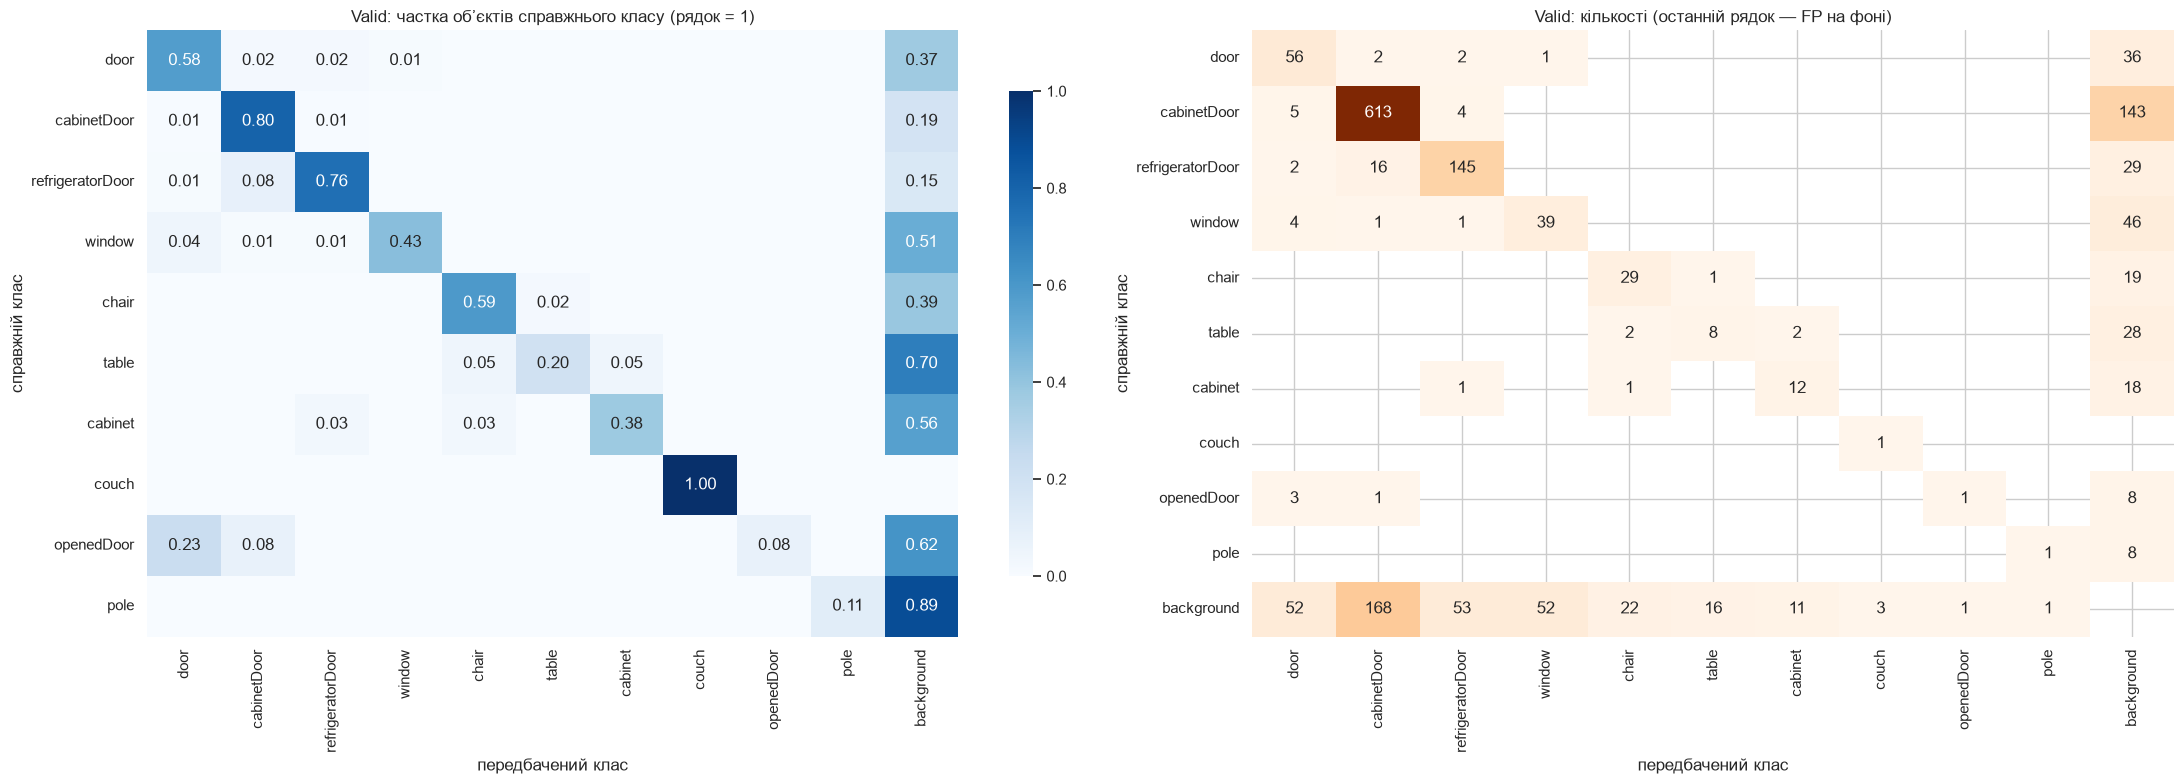

**Найчастіші плутанини між класами на valid**

,справжній,передбачено як,обʼєктів,частка класу
0,refrigeratorDoor,cabinetDoor,16,0.083
1,cabinetDoor,door,5,0.007
2,cabinetDoor,refrigeratorDoor,4,0.005
3,window,door,4,0.044
4,openedDoor,door,3,0.231
5,door,cabinetDoor,2,0.021
6,table,cabinet,2,0.050
7,refrigeratorDoor,door,2,0.010
8,door,refrigeratorDoor,2,0.021
9,table,chair,2,0.050


**Розбір по класах (conf ≥ 0.25)**

,GT обʼєктів,правильно,інший клас,пропущено (фон),FP на фоні,recall@0.25,частка пропусків
door,97,56,5,36,52,0.577,0.371
cabinetDoor,765,613,9,143,168,0.801,0.187
refrigeratorDoor,192,145,18,29,53,0.755,0.151
window,91,39,6,46,52,0.429,0.505
chair,49,29,1,19,22,0.592,0.388
table,40,8,4,28,16,0.200,0.700
cabinet,32,12,2,18,11,0.375,0.562
couch,1,1,0,0,3,1.000,0.000
openedDoor,13,1,4,8,1,0.077,0.615
pole,9,1,0,8,1,0.111,0.889


**Точність класифікації серед знайдених обʼєктів (GT зіставлено з рамкою будь-якого класу): 0.949**

In [18]:
BG = 'background'


def confusion_df(metrics) -> pd.DataFrame:
    """Rows = true class, columns = predicted class (Ultralytics stores matrix[pred, true])."""
    labels = CLASS_NAMES + [BG]
    return pd.DataFrame(metrics.confusion_matrix.matrix.T.astype(int), index=labels, columns=labels)


def plot_confusion(cm: pd.DataFrame, title: str):
    cm_n = cm.iloc[:NC].div(cm.iloc[:NC].sum(axis=1).replace(0, np.nan), axis=0)   # share of true objects
    annot = cm_n.map(lambda v: '' if pd.isna(v) or v < 0.005 else f'{v:.2f}')
    fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={'width_ratios': [1.1, 1]})
    sns.heatmap(cm_n, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar_kws={'shrink': 0.8})
    axes[0].set_title(f'{title}: частка обʼєктів справжнього класу (рядок = 1)')
    axes[0].set_ylabel('справжній клас')
    axes[0].set_xlabel('передбачений клас')
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[1], cbar=False,
                mask=(cm == 0).to_numpy())
    axes[1].set_title(f'{title}: кількості (останній рядок — FP на фоні)')
    axes[1].set_ylabel('справжній клас')
    axes[1].set_xlabel('передбачений клас')
    plt.tight_layout()
    plt.show()


def confusion_report(cm: pd.DataFrame, top: int = 10):
    core = cm.iloc[:NC, :NC]
    gt_total = cm.iloc[:NC].sum(axis=1)
    pairs = [(t, p, int(core.loc[t, p]), core.loc[t, p] / gt_total[t])
             for t in CLASS_NAMES for p in CLASS_NAMES if t != p and core.loc[t, p] > 0]
    pairs = (pd.DataFrame(pairs, columns=['справжній', 'передбачено як', 'обʼєктів', 'частка класу'])
             .sort_values('обʼєктів', ascending=False).head(top).reset_index(drop=True))
    per_class = pd.DataFrame({
        'GT обʼєктів': gt_total,
        'правильно': np.diag(core),
        'інший клас': core.sum(axis=1) - np.diag(core),
        'пропущено (фон)': cm.iloc[:NC][BG],
        'FP на фоні': cm.loc[BG, CLASS_NAMES],
    })
    per_class['recall@0.25'] = per_class['правильно'] / per_class['GT обʼєктів']
    per_class['частка пропусків'] = per_class['пропущено (фон)'] / per_class['GT обʼєктів']
    cls_acc = np.trace(core.to_numpy()) / core.to_numpy().sum()
    return pairs, per_class, cls_acc


val_cm = confusion_df(val_metrics)
plot_confusion(val_cm, 'Valid')
val_pairs, val_cm_pc, VAL_CLS_ACC = confusion_report(val_cm)
title('Найчастіші плутанини між класами на valid')
display(val_pairs)
title('Розбір по класах (conf ≥ 0.25)')
display(val_cm_pc)
title(f'Точність класифікації серед знайдених обʼєктів (GT зіставлено з рамкою будь-якого класу): {VAL_CLS_ACC:.3f}')

Для порівняння нормована матриця у форматі Ultralytics (там стовпці відповідають справжньому класу, нормування по стовпцях):

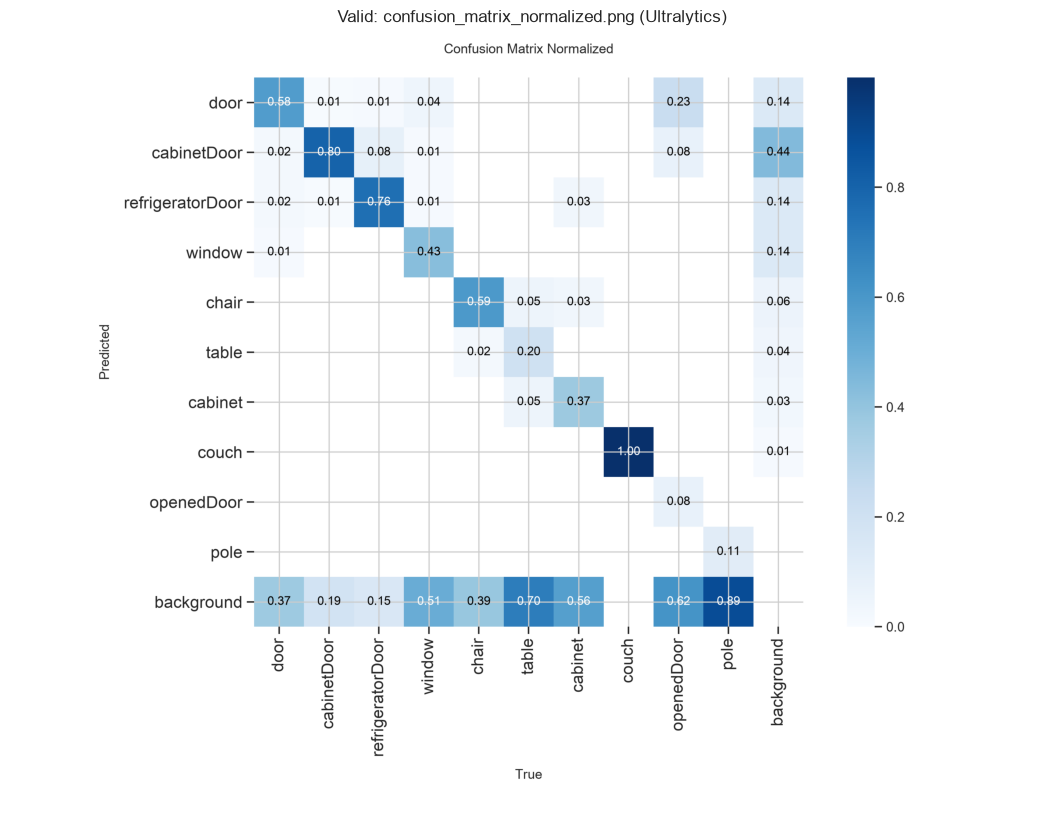

In [19]:
show_images([VAL_DIR / 'confusion_matrix_normalized.png'], ['Valid: confusion_matrix_normalized.png (Ultralytics)'],
            ncols=1, width=12)

Аналіз матриці помилок.

Основна проблема тут у пропусках обʼєктів, плутанина класів важить менше. Якщо модель поставила рамку на обʼєкт, клас правильний у 94.9 % випадків. А от частка пропущених обʼєктів (стовпчик background) велика: `pole` 89 %, `table` 70 %, `openedDoor` 62 %, `cabinet` 56 %, `window` 51 %, `chair` 39 %, `door` 37 %. У найкращих класів вона лише 19 % (`cabinetDoor`) і 15 % (`refrigeratorDoor`).

Які пари плутаються і чому:
* `refrigeratorDoor` → `cabinetDoor` (16 обʼєктів, 8 % дверцят холодильника) і навпаки (4). Обидва класи виглядають як плоскі прямокутні панелі з ручкою, часто однакового кольору (білі кухонні фасади поруч із вбудованим холодильником). Відрізняє їх контекст (розмір, морозильна камера, розташування), а контекст модель на 640 px бачить погано. На третьому прикладі в розділі 11.1 модель назвала бічну стінку холодильника `cabinetDoor`.
* `openedDoor` → `door` (3 з 13, 23 %). Це той самий обʼєкт в іншому стані, до того ж межа між прочиненими й зачиненими дверима в розмітці нечітка.
* `window` → `door` (4) і `cabinetDoor` → `door` (5). Засклені / балконні двері схожі на вікна, а високі дверцята шаф схожі на двері.
* `table` → `cabinet` і `table` → `chair` (по 2). Стіл часто закритий стільцями, а кухонний острів чи тумба виглядають як шафа.

Хибних спрацювань на фоні найбільше в `cabinetDoor` (168), `refrigeratorDoor` (53), `door` і `window` (по 52). Частина з них є зайвими рамками на частинах великих обʼєктів (на першому прикладі 11.1 верхні дверцята шафи розбито на дві рамки). Частина, можливо, припадає на нерозмічені обʼєкти: розмітка в таких датасетах буває неповною, і щоб це перевірити, треба переглянути FP вручну.

## 10. Оцінка на тестовій вибірці

На test роблю фінальну перевірку на зображеннях, які не брали участі ні в навчанні, ні у виборі епохи. Як видно з дослідження даних, у test інший розподіл класів і, ймовірно, інше джерело зображень.

In [20]:
test_metrics = evaluate('test')
test_pc = per_class_table(test_metrics)
TEST = overall(test_metrics, test_pc)
TEST_DIR = Path(test_metrics.save_dir)

Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 CPU (Apple M2 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4702.8±834.9 MB/s, size: 379.5 KB)
val: Scanning /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/test/labels.cache... 104 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 112.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 107/107 10.4it/s 10.3s
                   all        107        550      0.361      0.382      0.368      0.196
                  door         25         34      0.374      0.382      0.357      0.174
           cabinetDoor         42        179      0.597      0.536       0.51      0.193
      refrigeratorDoor          1          2      0.158          1      0.995      0.696
                window         49         63      0.472      0.524   

**Загальні метрики: valid vs test**

,P,R,mAP50,mAP50-95,F1 (середнє по класах),conf при max F1
valid,0.428,0.511,0.495,0.336,0.432,0.188
test,0.361,0.382,0.368,0.196,0.316,0.134


**Метрики по класах: valid vs test (відсортовано за F1 на valid)**

valid                                       test                                 
                 instances     P     R    F1 mAP50 mAP50-95 instances     P     R    F1 mAP50 mAP50-95
class                                                                                                 
cabinetDoor            765 0.717 0.799 0.755 0.794    0.443       179 0.597 0.536 0.565 0.510    0.193
refrigeratorDoor       192 0.681 0.778 0.726 0.771    0.519         2 0.158 1.000 0.273 0.995    0.696
chair                   49 0.499 0.592 0.542 0.580    0.325        87 0.375 0.425 0.399 0.340    0.173
door                    97 0.424 0.619 0.503 0.542    0.341        34 0.374 0.382 0.378 0.357    0.174
cabinet                 32 0.434 0.406 0.420 0.417    0.286        52 0.580 0.186 0.282 0.291    0.170
window                  91 0.367 0.429 0.396 0.344    0.217        63 0.472 0.524 0.497 0.445    0.262
couch                    1 0.225 1.000 0.367 0.995    0.995        58 0.262 0.345 0.298 0.215    0.089
table                   40 0.364 0.300 0.329 0.240    0.117        47 0.288 0.319 0.303 0.186    0.067
pole                     9 0.350 0.111 0.169 0.147    0.052         8 0.148 0.055 0.081 0.201    0.073
openedDoor              13 0.224 0.077 0.115 0.116    0.070        20 0.349 0.050 0.087 0.144    0.064

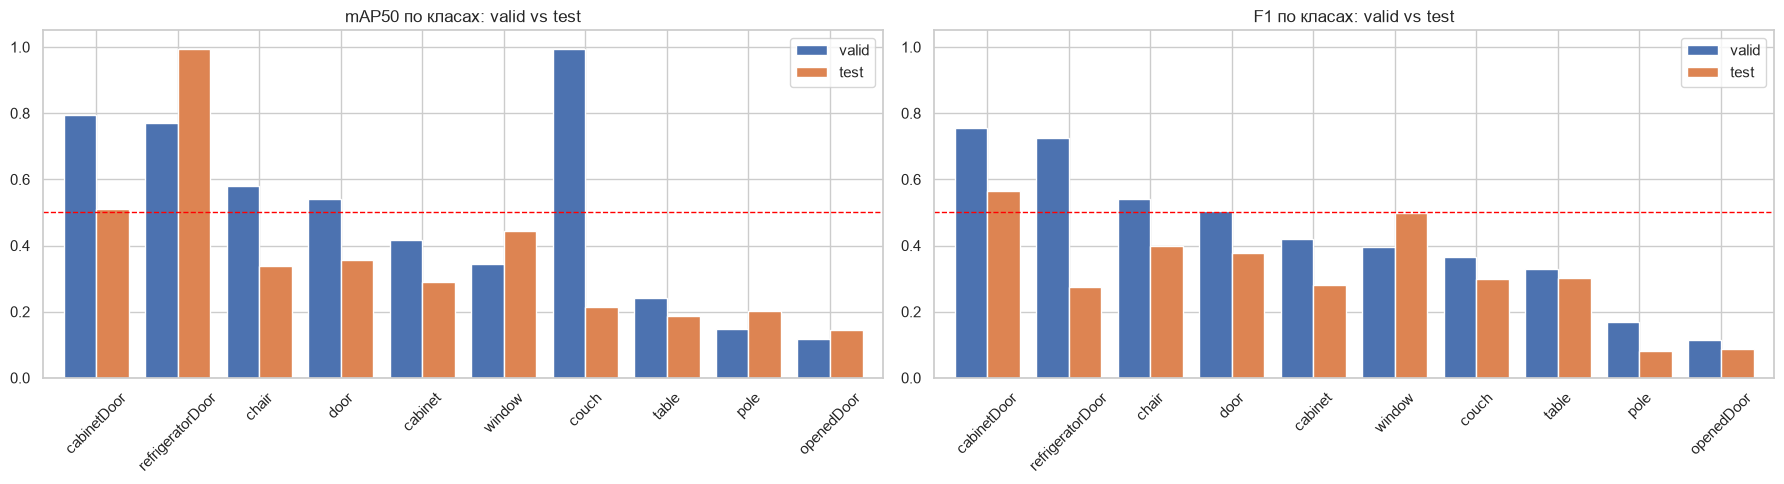

In [21]:
title('Загальні метрики: valid vs test')
display(pd.DataFrame([VAL, TEST], index=['valid', 'test']))

cmp = pd.concat({'valid': val_pc[['instances', 'P', 'R', 'F1', 'mAP50', 'mAP50-95']],
                 'test': test_pc[['instances', 'P', 'R', 'F1', 'mAP50', 'mAP50-95']]}, axis=1)
cmp = cmp.sort_values(('valid', 'F1'), ascending=False)
title('Метрики по класах: valid vs test (відсортовано за F1 на valid)')
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, metric in zip(axes, ['mAP50', 'F1']):
    pd.DataFrame({'valid': val_pc[metric], 'test': test_pc[metric]}).loc[cmp.index].plot(kind='bar', ax=ax, width=0.8)
    ax.axhline(0.5, color='red', ls='--', lw=1)
    ax.set_title(f'{metric} по класах: valid vs test')
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Чи повʼязана якість класу з кількістю навчальних прикладів? На точковій діаграмі по осі X кількість обʼєктів класу в train (лог. шкала), по осі Y mAP50 на valid і test.

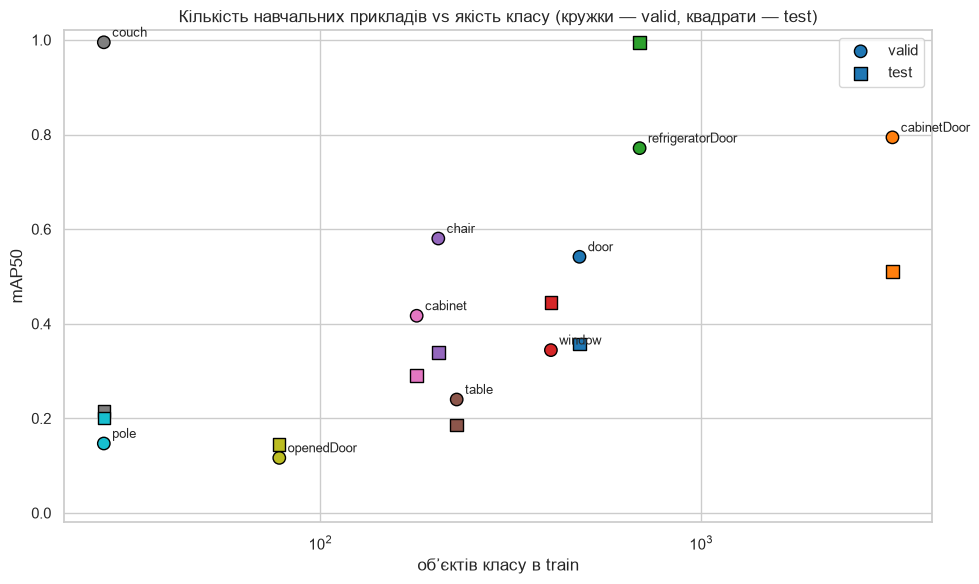

Кореляція Спірмена (кількість у train vs mAP50 на valid): 0.36
Кореляція Спірмена (кількість у train vs mAP50 на test): 0.79


In [22]:
n_train = inst['train']
fig, ax = plt.subplots(figsize=(10, 6))
for split_name, pc, marker in [('valid', val_pc, 'o'), ('test', test_pc, 's')]:
    ax.scatter(n_train.loc[pc.index], pc['mAP50'], s=80, marker=marker, label=split_name,
               c=[PALETTE[c] for c in pc.index], edgecolors='black')
for c in val_pc.index:
    ax.annotate(c, (n_train[c], val_pc.loc[c, 'mAP50']), textcoords='offset points', xytext=(6, 4), fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('обʼєктів класу в train')
ax.set_ylabel('mAP50')
ax.set_ylim(-0.02, 1.02)
ax.set_title('Кількість навчальних прикладів vs якість класу (кружки — valid, квадрати — test)')
ax.legend()
plt.tight_layout()
plt.show()
for split_name, pc in [('valid', val_pc), ('test', test_pc)]:
    rho = pd.Series(n_train.loc[pc.index]).rank().corr(pc['mAP50'].rank())
    print(f'Кореляція Спірмена (кількість у train vs mAP50 на {split_name}): {rho:.2f}')

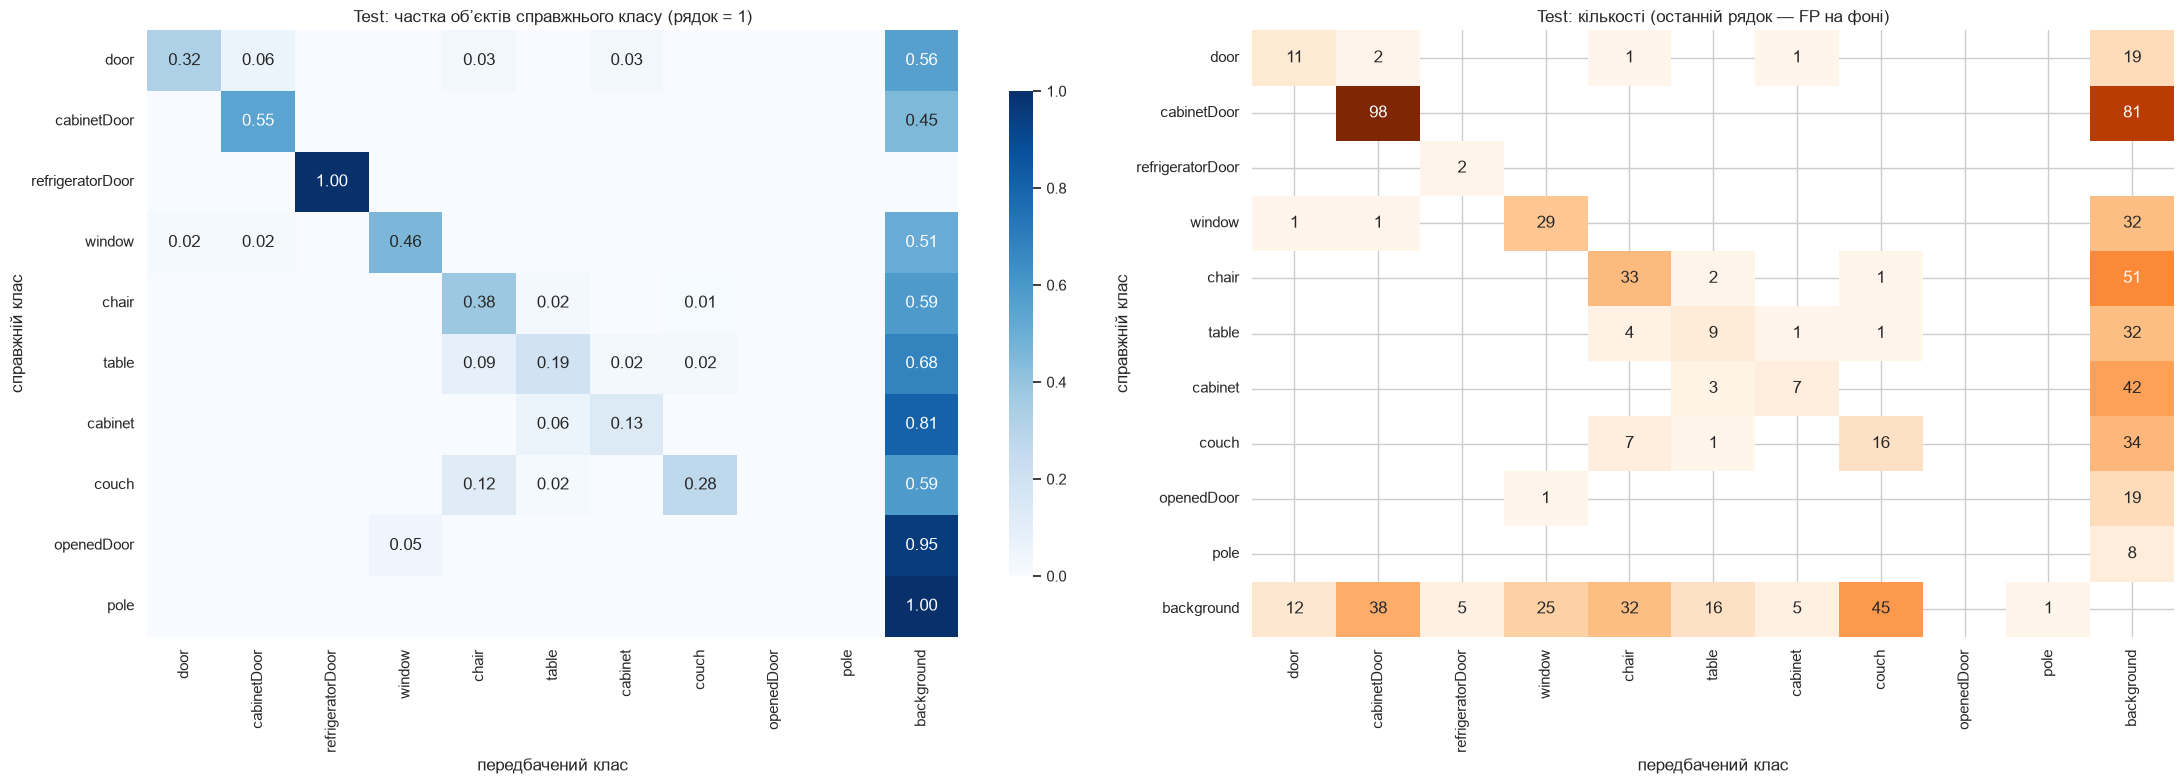

**Найчастіші плутанини на test**

,справжній,передбачено як,обʼєктів,частка класу
0,couch,chair,7,0.121
1,table,chair,4,0.085
2,cabinet,table,3,0.058
3,door,cabinetDoor,2,0.059
4,chair,table,2,0.023
5,door,chair,1,0.029
6,door,cabinet,1,0.029
7,window,door,1,0.016
8,window,cabinetDoor,1,0.016
9,chair,couch,1,0.011


**Розбір по класах на test (conf ≥ 0.25)**

,GT обʼєктів,правильно,інший клас,пропущено (фон),FP на фоні,recall@0.25,частка пропусків
door,34,11,4,19,12,0.324,0.559
cabinetDoor,179,98,0,81,38,0.547,0.453
refrigeratorDoor,2,2,0,0,5,1.000,0.000
window,63,29,2,32,25,0.460,0.508
chair,87,33,3,51,32,0.379,0.586
table,47,9,6,32,16,0.191,0.681
cabinet,52,7,3,42,5,0.135,0.808
couch,58,16,8,34,45,0.276,0.586
openedDoor,20,0,1,19,0,0.000,0.950
pole,8,0,0,8,1,0.000,1.000


**Точність класифікації серед знайдених обʼєктів на test: 0.884**

In [23]:
test_cm = confusion_df(test_metrics)
plot_confusion(test_cm, 'Test')
test_pairs, test_cm_pc, TEST_CLS_ACC = confusion_report(test_cm)
title('Найчастіші плутанини на test')
display(test_pairs)
title('Розбір по класах на test (conf ≥ 0.25)')
display(test_cm_pc)
title(f'Точність класифікації серед знайдених обʼєктів на test: {TEST_CLS_ACC:.3f}')

На test багато хибних спрацювань класу `couch` (рядок background у матриці). Щоб зрозуміти, звідки вони, відбираю зображення test, на яких модель (conf ≥ 0.25) передбачає більше диванів, ніж є в розмітці.

Зображень test, де передбачено більше диванів, ніж у розмітці: 18; зайвих рамок couch: 29


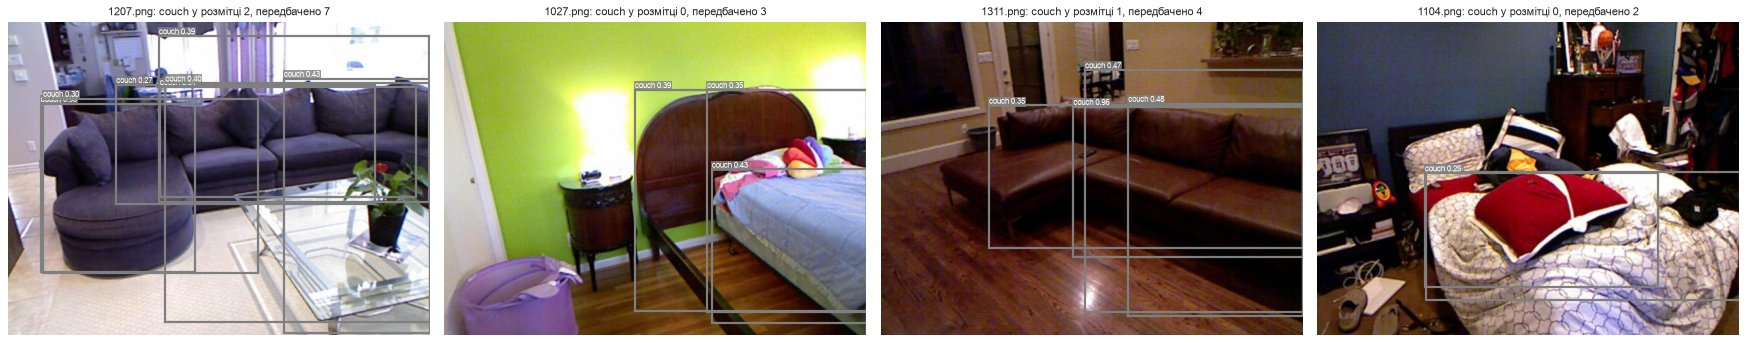

In [24]:
COUCH = CLASS_NAMES.index('couch')
couch_rows = []
for f in images_df.loc[images_df.split == 'test', 'file']:
    r = best_model.predict(DATA_ROOT / 'test' / 'images' / f, conf=0.25, imgsz=CFG.IMGSZ, device=EVAL_DEVICE,
                           verbose=False)[0]
    keep = (r.boxes.cls == COUCH).cpu().numpy()
    n_gt = int(((boxes_df.split == 'test') & (boxes_df.file == f) & (boxes_df.cls == COUCH)).sum())
    if keep.sum() > n_gt:
        boxes = np.column_stack([r.boxes.cls.cpu().numpy(), r.boxes.xywhn.cpu().numpy()])[keep]
        couch_rows.append((f, n_gt, int(keep.sum()), boxes, r.boxes.conf.cpu().numpy()[keep]))
couch_rows.sort(key=lambda x: x[2] - x[1], reverse=True)
print(f'Зображень test, де передбачено більше диванів, ніж у розмітці: {len(couch_rows)}; '
      f'зайвих рамок couch: {sum(p - g for _, g, p, _, _ in couch_rows)}')

fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
for ax, (f, n_gt, n_pred, boxes, conf) in zip(axes, couch_rows[:4]):
    img = Image.open(DATA_ROOT / 'test' / 'images' / f).convert('RGB')
    ax.imshow(img)
    draw_boxes(ax, boxes, *img.size, conf=conf)
    ax.set_title(f'{f}: couch у розмітці {n_gt}, передбачено {n_pred}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
show_jpeg(fig)

Порівняння valid і test:

* На test усі загальні метрики нижчі: mAP50 0.368 (на valid 0.495), mAP50-95 0.196 (0.336), P 0.361, R 0.382, середній F1 0.316. Орієнтиру з умови для mAP50 (40-60 %) на test модель не досягає.
* Причин дві. (1) Інший домен: тьмяні кадри 620×460 (схожі на кадри RGB-D-камери), яких у train лише 25 з 1012. (2) Інший склад класів: на test багато `chair` (87), `couch` (58), `cabinet` (52), `table` (47), тобто якраз тих класів, які модель знає гірше, а `refrigeratorDoor` має лише 2 обʼєкти (тому його mAP50 0.995 випадковий).
* `cabinetDoor` лишається найкращим класом (F1 0.755 → 0.565, mAP50 0.794 → 0.510). `door` (mAP50 0.542 → 0.357) і `chair` (0.580 → 0.340) помітно просіли. `window`, навпаки, покращився (0.344 → 0.445): на тестових кадрах вікна великі й яскраві (жалюзі проти світла). Для `couch` тепер є 58 обʼєктів, і видно, що диван модель майже не вивчила: mAP50 0.215 (у train лише 27 диванів).
* Точність класифікації серед знайдених обʼєктів на test 0.884 (на valid 0.949). Зʼявилися нові плутанини: `couch` → `chair` (7 з 58), `table` → `chair` (4), `cabinet` → `table` (3). Пара «диван / стілець» неоднозначна вже в розмітці: крісла в цьому датасеті розмічені як `couch`, а в COCO (звідки претреновані ваги) крісло позначене як `chair`. Це видно й на прикладі претренованої моделі в розділі 5.
* Хибних `couch` на фоні 45. На 18 тестових зображеннях модель передбачає більше диванів, ніж є в розмітці (29 зайвих рамок). На прикладах вище видно дві причини. Великий кутовий диван розбивається на кілька частково перекритих рамок, і NMS з порогом IoU 0.7 їх не прибирає. Крім того, ліжко модель приймає за диван, бо класу `bed` у датасеті немає, а спалень у train мало.
* Кореляція Спірмена між кількістю обʼєктів класу в train і mAP50 на test дорівнює 0.79: чим більше прикладів, тим краще клас розпізнається. На valid вона лише 0.36, бо її «ламають» класи з кількома обʼєктами у val (`couch` 1, `pole` 9, `openedDoor` 13), чиї AP майже випадкові.

## 11. Передбачення на зображеннях, recall за розміром обʼєктів і TTA

### 11.1. Приклади: розмітка vs передбачення
Ліворуч ground truth, праворуч передбачення `best.pt` з порогом confidence, при якому середній F1 на valid максимальний (його розраховано в розділі 8). Показую по 3 випадкові зображення з valid і test, на кожному є обʼєкти щонайменше двох класів.

Поріг confidence для візуалізації: 0.19


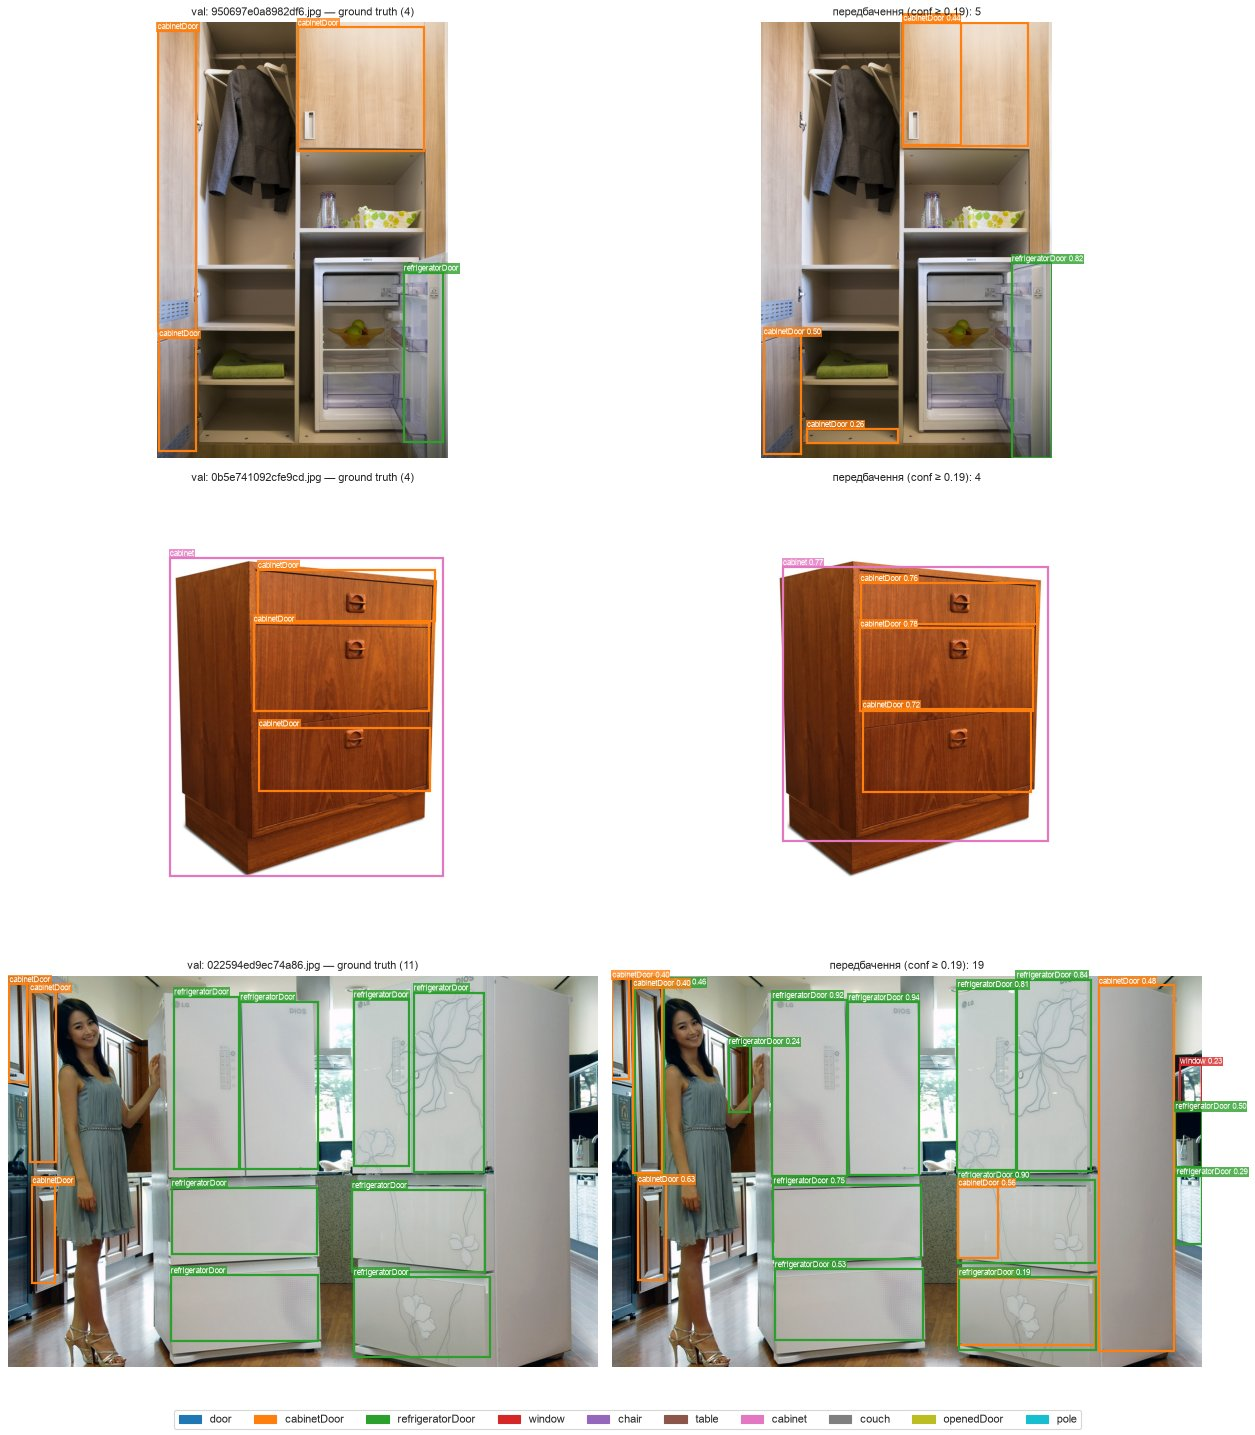

In [25]:
CONF_THR = round(VAL['conf при max F1'], 2)


def predict_boxes(path, conf=CONF_THR):
    r = best_model.predict(path, conf=conf, imgsz=CFG.IMGSZ, device=EVAL_DEVICE, verbose=False)[0]
    H, W = r.orig_shape
    xywhn = r.boxes.xywhn.cpu().numpy()
    cls = r.boxes.cls.cpu().numpy()
    return np.column_stack([cls, xywhn]) if len(cls) else np.zeros((0, 5)), r.boxes.conf.cpu().numpy(), W, H


def show_predictions(split: str, k: int = 3, seed: int = SEED):
    multi = (boxes_df[boxes_df.split == split].groupby('file')['cls'].nunique() >= 2)
    files = sorted(multi[multi].index)
    files = random.Random(seed).sample(files, k)
    fig, axes = plt.subplots(k, 2, figsize=(16, 6 * k))
    for row, f in zip(axes, files):
        path = DATA_ROOT / SPLITS[split] / 'images' / f
        img = Image.open(path).convert('RGB')
        pred, conf, W, H = predict_boxes(path)
        gt = gt_boxes(split, f)
        row[0].imshow(img)
        draw_boxes(row[0], gt, W, H)
        row[0].set_title(f'{split}: {f[:30]} — ground truth ({len(gt)})', fontsize=10)
        row[1].imshow(img)
        draw_boxes(row[1], pred, W, H, conf=conf)
        row[1].set_title(f'передбачення (conf ≥ {CONF_THR}): {len(pred)}', fontsize=10)
        for ax in row:
            ax.axis('off')
    fig.legend(handles=legend_handles(), loc='lower center', ncol=NC, fontsize=10)
    plt.tight_layout(rect=(0, 0.02, 1, 1))
    show_jpeg(fig)


print(f'Поріг confidence для візуалізації: {CONF_THR}')
show_predictions('val')

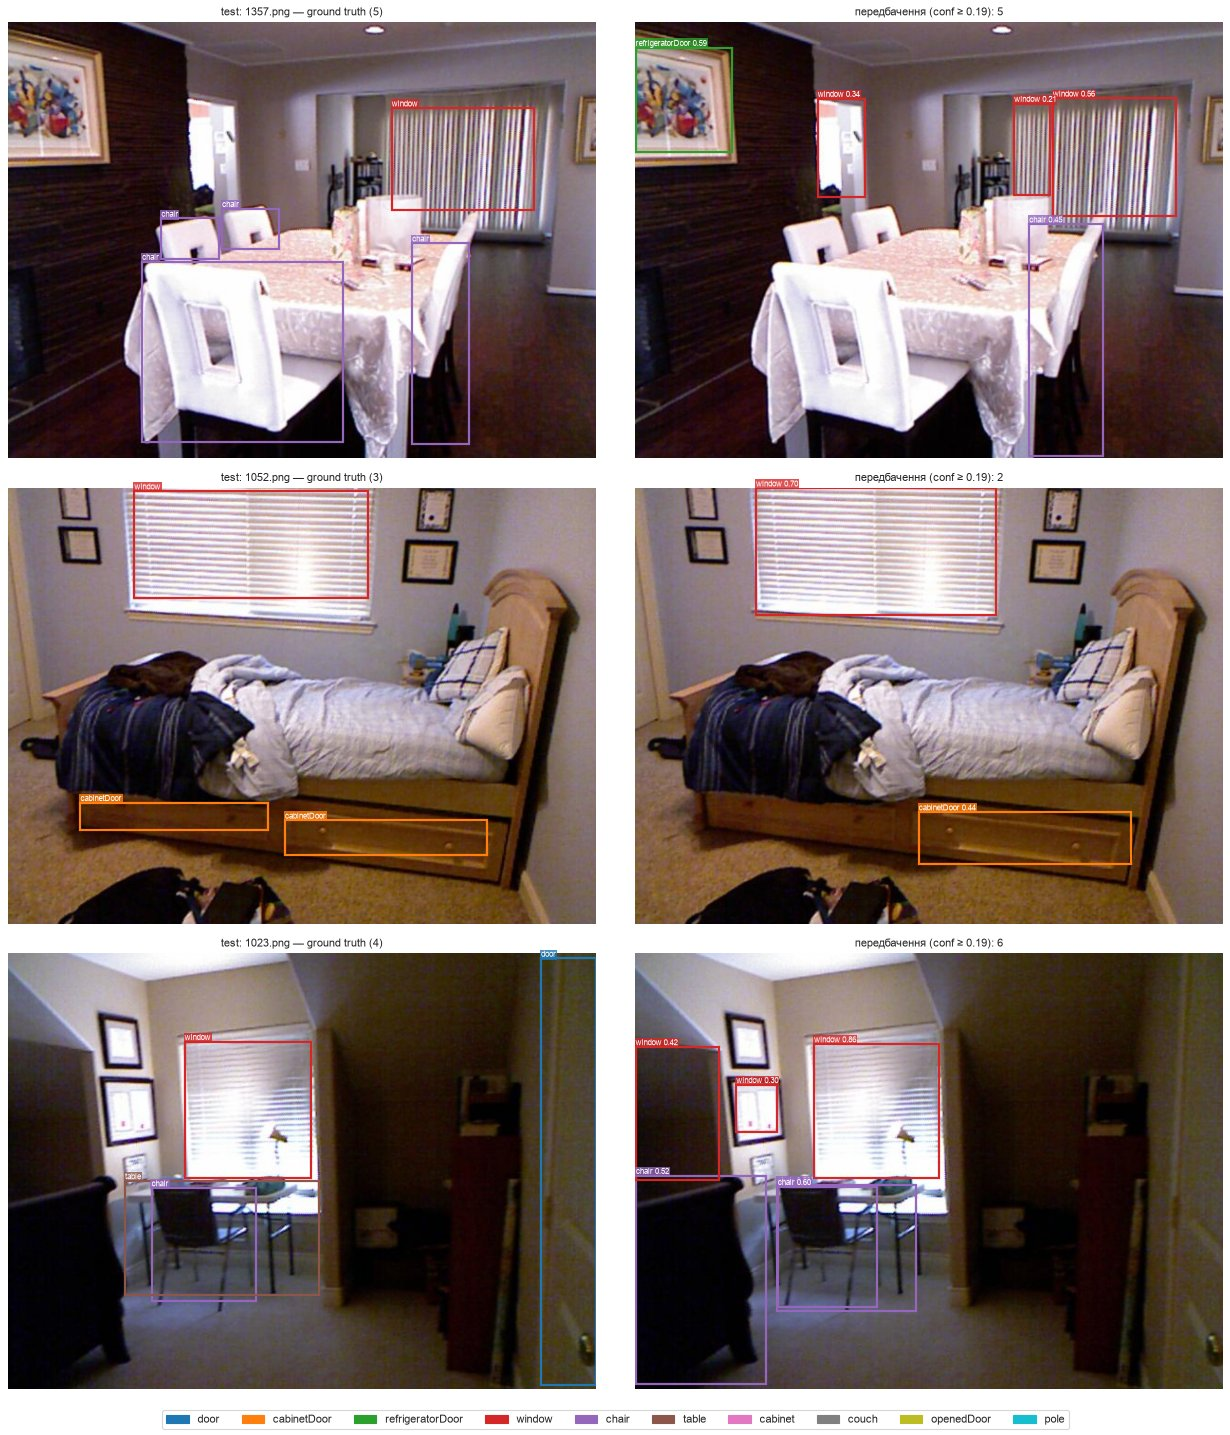

In [26]:
show_predictions('test')

### 11.2. Recall залежно від розміру обʼєкта
Для кожної рамки ground truth перевіряю, чи є передбачення того самого класу з IoU ≥ 0.5 (при тому ж порозі confidence). Рамки групую за розміром обʼєкта на вході мережі 640 px: small < 32², medium, large > 96² пікселів, як у COCO.

In [27]:
def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """IoU between boxes given as normalised (xc, yc, w, h)."""
    def xyxy(x):
        return np.column_stack([x[:, 0] - x[:, 2] / 2, x[:, 1] - x[:, 3] / 2, x[:, 0] + x[:, 2] / 2, x[:, 1] + x[:, 3] / 2])
    A, B = xyxy(a), xyxy(b)
    lt = np.maximum(A[:, None, :2], B[None, :, :2])
    rb = np.minimum(A[:, None, 2:], B[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(axis=2)
    area_a = (A[:, 2:] - A[:, :2]).prod(axis=1)
    area_b = (B[:, 2:] - B[:, :2]).prod(axis=1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match_gt(split: str) -> pd.DataFrame:
    gt = boxes_df[boxes_df.split == split].copy()
    gt['detected'] = False
    for f, g in gt.groupby('file'):
        pred, _, _, _ = predict_boxes(DATA_ROOT / SPLITS[split] / 'images' / f)
        if not len(pred):
            continue
        iou = iou_matrix(g[['xc', 'yc', 'w', 'h']].to_numpy(), pred[:, 1:])
        same_cls = g['cls'].to_numpy()[:, None] == pred[:, 0][None, :]
        gt.loc[g.index, 'detected'] = ((iou >= 0.5) & same_cls).any(axis=1)
    return gt


matched = pd.concat([match_gt('val'), match_gt('test')])
by_size = matched.pivot_table(index='split', columns='size_bucket', values='detected', aggfunc=['mean', 'size'],
                              observed=False).reindex(['val', 'test'])
title('Recall (IoU ≥ 0.5, той самий клас) за розміром обʼєкта')
display(by_size)
by_cls_size = matched[matched.split == 'val'].pivot_table(index='name', columns='size_bucket', values='detected',
                                                          aggfunc='mean', observed=False).reindex(CLASS_NAMES)
by_cls_size['n'] = matched[matched.split == 'val'].groupby('name').size()
title('Valid: recall по класах і розмірах (NaN — обʼєктів такого розміру немає)')
display(by_cls_size)

**Recall (IoU ≥ 0.5, той самий клас) за розміром обʼєкта**

mean                             size                    
size_bucket small (<32²) medium large (>96²) small (<32²) medium large (>96²)
split                                                                        
val                0.489  0.761        0.697           88    669          532
test               0.206  0.404        0.473           68    218          264

**Valid: recall по класах і розмірах (NaN — обʼєктів такого розміру немає)**

size_bucket,small (<32²),medium,large (>96²),n
name,,,,
door,NaN,0.562,0.662,97
cabinetDoor,0.545,0.838,0.787,765
refrigeratorDoor,0.000,0.679,0.791,192
window,0.263,0.429,0.600,91
chair,1.000,0.444,0.724,49
table,NaN,0.000,0.414,40
cabinet,NaN,1.000,0.419,32
couch,NaN,NaN,1.000,1
openedDoor,NaN,0.000,0.091,13


* На valid recall для малих обʼєктів (< 32² px на вході 640) дорівнює 0.49, для середніх 0.76, для великих 0.70. На test ці значення 0.21 / 0.40 / 0.47. Дрібні обʼєкти (далекі фасади, маленькі вікна) модель пропускає помітно частіше, і це аргумент за більший `imgsz`.
* Великі обʼєкти в середньому не найкращі, бо серед них багато складних класів: recall великих `table` 0.41, `cabinet` 0.42, `openedDoor` 0.09. Для цих класів проблема в малій кількості й неоднозначності прикладів, розмір її не пояснює.

### 11.3. Швидка перевірка одного покращення без перенавчання: TTA
Test-Time Augmentation (`augment=True`): під час передбачення зображення додатково обробляється у зміненому масштабі та з віддзеркаленням, а результати обʼєднуються. Перевіряю, чи дає це приріст на valid (і для контролю на test).

In [28]:
tta_rows = {}
for split in ['val', 'test']:
    m = best_model.val(data=str(DATA_YAML), split=split, imgsz=CFG.IMGSZ, batch=EVAL_BATCH, device=EVAL_DEVICE,
                       augment=True, plots=False, verbose=False, project=str(CFG.PROJECT),
                       name=f'eval_{split}_tta', exist_ok=True)
    tta_rows[f'{split} + TTA'] = {'P': m.box.mp, 'R': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}
base_rows = {s: {k: d[k] for k in ['P', 'R', 'mAP50', 'mAP50-95']} for s, d in [('val', VAL), ('test', TEST)]}
tta_df = pd.DataFrame({**base_rows, **tta_rows}).T.loc[['val', 'val + TTA', 'test', 'test + TTA']]
display(tta_df)

Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 CPU (Apple M2 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4069.6±1519.3 MB/s, size: 265.3 KB)
val: Scanning /Users/faridjafarli/.cache/kagglehub/datasets/thepbordin/indoor-object-detection/versions/1/valid/labels.cache... 230 images, 31 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 321.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 230/230 4.0it/s 56.8s
                   all        230       1289      0.462       0.51      0.508      0.334
Speed: 0.3ms preprocess, 240.0ms inference, 0.0ms loss, 0.6ms postprocess per image
Ultralytics 8.4.163 🚀 Python-3.12.3 torch-2.14.0 CPU (Apple M2 Max)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3917.3±685.3 MB/s, size: 311.9 KB)
val: Scanning

,P,R,mAP50,mAP50-95
val,0.428,0.511,0.495,0.336
val + TTA,0.462,0.510,0.508,0.334
test,0.361,0.382,0.368,0.196
test + TTA,0.460,0.371,0.406,0.230


* На valid TTA майже нічого не дає: mAP50 0.495 → 0.508 (+0.013), mAP50-95 0.336 → 0.334 (−0.002), а інференс на CPU повільніший у ≈ 2.7 раза (248 мс проти 92 мс на зображення).
* На test приріст помітніший: mAP50 0.368 → 0.406, mAP50-95 0.196 → 0.230, P 0.361 → 0.460. Зміна масштабу допомагає на кадрах іншого домену й іншої роздільності.
* Рішення за тестом я не ухвалюю. За valid TTA не виправдовує в 2.7 раза довшого інференсу. Для нових камер чи приміщень цю ідею варто перевірити на окремій вибірці з цільового домену.

## 12. Чи досягнуто мети: скільки класів модель розпізнає надійно

Критерій «надійно розпізнає клас» я взяв суворіший за просте «знаходить»: на valid mAP50 ≥ 0.5 і F1 ≥ 0.5. Для контролю показую ті самі метрики на test. Умова заліку вимагає щонайменше 3 з 10 класів. Колонка «примітка» позначає класи, у яких у вибірці менше 10 обʼєктів. Їхні метрики ненадійні (наприклад, `couch` у valid має 1 обʼєкт, `refrigeratorDoor` у test має 2).

In [29]:
goal = pd.DataFrame({
    'val mAP50': val_pc['mAP50'], 'val F1': val_pc['F1'],
    'test mAP50': test_pc['mAP50'], 'test F1': test_pc['F1'],
    'val instances': val_pc['instances'], 'test instances': test_pc['instances'],
})
goal['надійно (val)'] = (goal['val mAP50'] >= 0.5) & (goal['val F1'] >= 0.5)
goal['надійно і на test'] = goal['надійно (val)'] & (goal['test mAP50'] >= 0.5) & (goal['test F1'] >= 0.5)
goal['примітка'] = np.where(goal['val instances'] < 10, 'у val < 10 обʼєктів',
                            np.where(goal['test instances'] < 10, 'у test < 10 обʼєктів', ''))
goal = goal.sort_values('val F1', ascending=False)
display(goal)

reliable = goal.index[goal['надійно (val)']].tolist()
reliable_both = goal.index[goal['надійно і на test']].tolist()
print(f'Надійно розпізнаються на valid: {len(reliable)} з {NC}: {reliable}')
print(f'...і підтверджено на test: {len(reliable_both)} з {NC}: {reliable_both}')
print('Мету (≥ 3 класи з 10) ДОСЯГНУТО' if len(reliable) >= 3 else 'Мету (≥ 3 класи з 10) НЕ досягнуто')

,val mAP50,val F1,test mAP50,test F1,val instances,test instances,надійно (val),надійно і на test,примітка
class,,,,,,,,,
cabinetDoor,0.794,0.755,0.510,0.565,765,179,True,True,
refrigeratorDoor,0.771,0.726,0.995,0.273,192,2,True,False,у test < 10 обʼєктів
chair,0.580,0.542,0.340,0.399,49,87,True,False,
door,0.542,0.503,0.357,0.378,97,34,True,False,
cabinet,0.417,0.420,0.291,0.282,32,52,False,False,
window,0.344,0.396,0.445,0.497,91,63,False,False,
couch,0.995,0.367,0.215,0.298,1,58,False,False,у val < 10 обʼєктів
table,0.240,0.329,0.186,0.303,40,47,False,False,
pole,0.147,0.169,0.201,0.081,9,8,False,False,у val < 10 обʼєктів


Надійно розпізнаються на valid: 4 з 10: ['cabinetDoor', 'refrigeratorDoor', 'chair', 'door']
...і підтверджено на test: 1 з 10: ['cabinetDoor']
Мету (≥ 3 класи з 10) ДОСЯГНУТО


In [30]:
summary = {
    'model': CFG.BASE_MODEL, 'device': DEVICE_NAME, 'epochs_planned': CFG.EPOCHS, 'epochs_run': N_EPOCHS_RUN,
    'best_epoch': BEST_EPOCH, 'train_minutes': round(TRAIN_MINUTES, 1), 'imgsz': CFG.IMGSZ, 'batch': CFG.BATCH,
    'val': {k: round(float(v), 4) for k, v in VAL.items()},
    'test': {k: round(float(v), 4) for k, v in TEST.items()},
    'val_classification_accuracy': round(float(VAL_CLS_ACC), 4),
    'test_classification_accuracy': round(float(TEST_CLS_ACC), 4),
    'val_per_class': val_pc.round(4).to_dict(orient='index'),
    'test_per_class': test_pc.round(4).to_dict(orient='index'),
    'reliable_classes_val': reliable, 'reliable_classes_val_and_test': reliable_both,
}
Path('results_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float))
print(json.dumps({k: v for k, v in summary.items() if 'per_class' not in k}, indent=2, ensure_ascii=False, default=float))

{
  "model": "yolov9s",
  "device": "MPS: Apple M2 Max GPU",
  "epochs_planned": 60,
  "epochs_run": 56,
  "best_epoch": 36,
  "train_minutes": 56.7,
  "imgsz": 640,
  "batch": 16,
  "val": {
    "P": 0.4285,
    "R": 0.511,
    "mAP50": 0.4946,
    "mAP50-95": 0.3365,
    "F1 (середнє по класах)": 0.4321,
    "conf при max F1": 0.1882
  },
  "test": {
    "P": 0.3605,
    "R": 0.3823,
    "mAP50": 0.3683,
    "mAP50-95": 0.196,
    "F1 (середнє по класах)": 0.3163,
    "conf при max F1": 0.1341
  },
  "val_classification_accuracy": 0.9486,
  "test_classification_accuracy": 0.8836,
  "reliable_classes_val": [
    "cabinetDoor",
    "refrigeratorDoor",
    "chair",
    "door"
  ],
  "reliable_classes_val_and_test": [
    "cabinetDoor"
  ]
}


## 13. Висновки

Я дослідив датасет (10 класів, сильний дисбаланс, test з іншого джерела), створив `data.yaml` і донавчив претреновану на COCO YOLOv9s (7.3 млн параметрів) на Apple M2 Max (MPS). Навчання пройшло 56 епох з 60 (рання зупинка, найкраща епоха 36-та) і тривало ≈ 57 хв (imgsz 640, batch 16, AdamW). Ваги лежать у `weights/best.pt`. Потім я оцінив модель на valid і test, розібрав криві навчання, метрики й F1 по класах, матрицю помилок і помилки за розміром обʼєктів, а також перевірив TTA.

Результат:

| Вибірка | P | R | mAP50 | mAP50-95 | F1 (середнє) |
|---|---|---|---|---|---|
| valid | 0.428 | 0.511 | 0.495 | 0.336 | 0.432 |
| test | 0.361 | 0.382 | 0.368 | 0.196 | 0.316 |

На valid mAP50 і mAP50-95 потрапляють в орієнтовні межі з умови (40-60 % і 25-40 %). На test результат нижчий, бо тестові кадри взяті з іншого джерела (інша камера, тьмяніші) і мають інший склад класів.

Найкраще модель розпізнає `cabinetDoor` (F1 0.76 на valid / 0.57 на test), `refrigeratorDoor` (0.73 на valid), `chair` (0.54) і `door` (0.50). Це класи, для яких у train найбільше прикладів, або ті, що є в COCO, як стілець. Найгірші `openedDoor` (F1 0.12), `pole` (0.17) і `table` (0.33 / 0.30), а `couch` на test має лише mAP50 0.215. У train усього 27 диванів, 27 стовпів і 78 відчинених дверей.

Якщо обʼєкт знайдено, клас майже завжди правильний (94.9 % на valid). Тож головна проблема в пропусках рідкісних і великих «неоднозначних» обʼєктів (стіл, шафа, відчинені двері, стовп). Плутаються візуально схожі пари: дверцята холодильника ↔ дверцята шафи, відчинені ↔ зачинені двері, вікно ↔ двері, диван ↔ стілець (крісла в розмітці позначені `couch`, а в COCO `chair`). Криві навчання показують перенавчання після ~25-35 епох: train loss далі падає, а val loss і mAP стоять на місці. На test додається зсув домену: ліжка модель приймає за дивани, а кутові дивани розбиває на кілька рамок.

YOLOv9s для такої задачі підходить. Це швидкий одноетапний anchor-free детектор з GELAN-backbone, а претреновані ваги COCO дали хороший старт (уже після 1-ї епохи mAP50 ≈ 0.29). Недоліки я теж побачив. Мала модель з входом 640 px гірше бачить дрібні обʼєкти (recall малих обʼєктів 0.49 проти 0.76 для середніх). Крім того, локальні ознаки погано розрізняють класи, які відрізняються контекстом (холодильник vs кухонна шафа).

Що я б зробив далі:
1. Найбільше дасть робота з даними. Доразмітити або дозібрати рідкісні класи (`couch` і `pole` мають по 27 прикладів, `openedDoor` 78) хоча б до кількох сотень обʼєктів. Додати в train кадри з домену test (RGB-D, спальні й вітальні; зараз їх 25). Перевірити повноту розмітки там, де модель дає багато хибних `cabinetDoor`.
2. Проти дисбалансу додати ваги класів у функцію втрат (в Ultralytics 8.4 це параметр `cls_pw`, наприклад `cls_pw=0.5`: вага класу ∝ (1/частота)^0.5) або oversampling зображень з рідкісними класами (повторити їх у списку train у 3-5 разів), а також `copy_paste`-аугментацію для рідкісних обʼєктів.
3. Переглянути класи. Обʼєднати `door` і `openedDoor` в один клас (а стан дверей визначати окремою класифікаційною моделлю поверх рамки) або чіткіше розмітити межу між ними. Щоб розрізняти дверцята холодильника й шафи, додати клас «холодильник» цілком. Додати клас `bed`, щоб ліжка не ставали хибними диванами.
4. Збільшити вхід і модель: `imgsz` від 832 до 1024 для дрібних обʼєктів і більша модель (YOLOv9m / YOLO11m). На GPU Kaggle це реально за 1-2 години. Альтернативи: RT-DETR (трансформер, краще використовує контекст сцени) або Faster R-CNN + FPN (точніше локалізує дрібні обʼєкти, але повільніший).
5. Змінити навчання. Просто збільшувати кількість епох без інших змін немає сенсу, бо val loss не падає з ~25-35-ї епохи. Краще взяти сильніші аугментації (`mixup`, `copy_paste`, `perspective` / `degrees` для кадрів під кутом, яскравість для тьмяних кадрів), `cos_lr` і підбір гіперпараметрів через `model.tune()`. Ще варто зробити більшу val-вибірку або крос-валідацію, щоб вибір найкращої епохи менше залежав від шуму.
6. На інференсі підібрати окремий поріг confidence для кожного класу за F1-кривими. TTA вмикати, лише якщо він підтвердиться на валідації з цільового домену (на valid він не дав приросту, на test дав +0.04 mAP50).

**Мету досягнуто.** За моїм критерієм (на valid mAP50 ≥ 0.5 і F1 ≥ 0.5) модель надійно розпізнає 4 класи з 10: `cabinetDoor`, `refrigeratorDoor`, `chair`, `door`. Це більше за потрібні 3, і серед них є двері й стільці, які умова називає найпоширенішими. На test (інший домен) цей поріг проходить лише `cabinetDoor`. Двері й стільці модель там знаходить, але менш надійно (mAP50 ≈ 0.34-0.36). Столи (`table`) надійно не розпізнаються ні на valid (mAP50 0.24), ні на test (0.19), тож їх варто покращувати першими разом із рідкісними класами.